# TTK4115 — Helicopter Lab 3 (Part III) | plot and data inspection
## Only Lab 3 (Luenberger observer) material

This notebook covers only **Part III: IMU characteristics, transformations and the Luenberger observer**. Its main source is `Del 3(1).zip`; the second archive `Del 4(1).zip` was inspected **only to recover recordings labelled `task34_*`** that could relate to Part III. No Kalman-filter recordings or figures are included.

The three 90.54-s `task34_*` main files share a time axis and can be compared directly. The additional `task34_*` recordings in `data/Tillegg_Lab3_fra_annet_arkiv/` are **unmatched recordings**, not a second synchronized experiment.

The audit on 7 November 2026 checked the recorded signals against the saved Simulink connections, and distinguished traceable signals from unmatched additional files. The original MATLAB/Simulink files contain potential model-implementation errors; this plotting notebook does not assume these were active during the recordings. See `Lab3_Feilsjekk_og_Mangler.pdf`.

All plots are exported to `figures/` as PNG and SVG. `Lab3_filoversikt.csv` identifies only the files delivered for this lab, including their original location and SHA-256 hash.

**Terminology:** `y` is an IMU-derived measurement vector, not encoder ground truth; the residual `y - xhat` is therefore *not* a true state-estimation error.


In [1]:
from pathlib import Path
from io import BytesIO
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import welch
from IPython.display import display

# ----------------------------- User settings -----------------------------
DATA_DIR = Path('data/Hovedopptak_Del3')     # Included in the downloadable package
ORIGINAL_ZIP = Path('Del 3(1).zip')   # Fallback when running next to the original ZIP
EXTRA_DIR = Path('data/Tillegg_Lab3_fra_annet_arkiv')
FIGURE_DIR = Path('figures')
SAVE_FIGURES = True
FIGURE_FORMATS = ('png', 'svg')
PNG_DPI = 200

# Time window for plots, in seconds. Use (None, None) to show the full run.
TIME_WINDOW_TASK2 = (None, None)
TIME_WINDOW_TASK3 = (None, None)
# Statistics are calculated over the complete Task 3 recording by default.
METRICS_WINDOW_TASK3 = (None, None)
MAX_POINTS_PER_LINE = 9000  # For full-run figures. Set to None for all raw points.
# The zoom windows below always plot at full sample resolution.
ZOOM_WINDOW_TASK2 = (20.0, 26.0)        # Task 2: a prominent transient
ZOOM_WINDOW_TASK3 = (38.0, 45.0)        # Task 3: transient in multiple states
STARTUP_WINDOW_TASK3 = (0.0, 8.0)  # Initialization and early motion (full resolution)
RESIDUAL_TREND_SECONDS = 1.0  # Centered rolling mean, diagnostic only
IMU_DETAIL_WINDOW = (15.00, 15.16)    # Short interval to inspect repeated samples

plt.rcParams.update({
    'figure.figsize': (11, 4.4),
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.fontsize': 9,
    'savefig.bbox': 'tight',
    'axes.grid': True,
    'grid.alpha': .24,
    'figure.dpi': 105,
})
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
exported = []


def load_recording(name):
    # Load a MATLAB recording from data/ or from original ZIP.
    local = DATA_DIR / name
    if local.is_file():
        mat = loadmat(local)
    elif ORIGINAL_ZIP.is_file():
        with zipfile.ZipFile(ORIGINAL_ZIP) as z:
            match = next((path for path in z.namelist()
                          if Path(path).name.casefold() == name.casefold()), None)
            if match is None:
                raise FileNotFoundError(f'{name!r} not found in {ORIGINAL_ZIP}')
            mat = loadmat(BytesIO(z.read(match)))
    else:
        raise FileNotFoundError(
            f'Missing {name!r}. Extract the package, keeping the data/ folder next '
            f'to the notebook, or place Del 3(1).zip next to the notebook.'
        )
    if 'ans' not in mat:
        raise KeyError(f"File {name!r}: expected MATLAB variable 'ans', found {list(mat)}")
    arr = np.asarray(mat['ans'], dtype=float)
    if arr.ndim != 2 or not np.isfinite(arr).all():
        raise ValueError(f'Unexpected dimensions / non-finite data in {name}: {arr.shape}')
    return arr


def time_series(name, channels=None):
    # Convert MATLAB timeseries row-major layout into (t, X).
    raw = load_recording(name)
    if raw.shape[1] < 3:
        raise ValueError(f'{name} is a snapshot, not a time series: shape {raw.shape}')
    t = raw[0].copy()
    x = raw[1:].T.copy()
    if np.any(np.diff(t) <= 0):
        raise ValueError(f'Non-monotonic time axis in {name}')
    if channels is not None and x.shape[1] != channels:
        raise ValueError(f'{name}: expected {channels} channels, got {x.shape[1]}')
    return t, x


def mask_time(t, window):
    t0, t1 = window
    return ((t >= t0) if t0 is not None else np.ones(t.size, bool)) & \
           ((t <= t1) if t1 is not None else np.ones(t.size, bool))


def indices_for_plot(t, window, force_full=False):
    idx = np.flatnonzero(mask_time(t, window))
    if idx.size == 0:
        raise ValueError(f'Time window {window} contains no samples.')
    if force_full or MAX_POINTS_PER_LINE is None:
        return idx
    if MAX_POINTS_PER_LINE <= 0:
        raise ValueError('MAX_POINTS_PER_LINE must be positive or None.')
    stride = max(1, int(np.ceil(idx.size / MAX_POINTS_PER_LINE)))
    # Preserve the final point even when the full-run series is decimated.
    chosen = idx[::stride]
    if chosen[-1] != idx[-1]:
        chosen = np.r_[chosen, idx[-1]]
    return chosen


def export_figure(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        for fmt in FIGURE_FORMATS:
            target = FIGURE_DIR / f'{name}.{fmt}'
            fig.savefig(target, dpi=PNG_DPI)
            exported.append(target)
    plt.show()


def stacked_plot(t, x, labels, units, title, name, window=(None, None),
                 comparison=None, comparison_label=None, data_label='Recorded',
                 full_resolution=False):
    if x.shape[1] != len(labels) or x.shape[1] != len(units):
        raise ValueError('Number of labels or units does not match signal count.')
    if comparison is not None and comparison.shape != x.shape:
        raise ValueError(f'Comparison shape {comparison.shape} does not match {x.shape}.')
    idx = indices_for_plot(t, window, force_full=full_resolution)
    fig, axes = plt.subplots(len(labels), 1, figsize=(12, 2.15*len(labels)),
                             sharex=True, squeeze=False)
    for k, ax in enumerate(axes.ravel()):
        ax.plot(t[idx], x[idx, k], label=data_label, linewidth=1.05)
        if comparison is not None:
            ax.plot(t[idx], comparison[idx, k], label=comparison_label, linewidth=1.15)
            if k == 0:
                ax.legend(loc='best')
        ax.set_ylabel(f'{labels[k]} [{units[k]}]')
    axes[-1, 0].set_xlabel('Time [s]')
    fig.suptitle(title, fontsize=13, y=1.005)
    export_figure(fig, name)

print('Ready. Figures will be saved to:', FIGURE_DIR.resolve())

Ready. Figures will be saved to: /mnt/data/Lab3_Kvalitetssikret_2026-11-07/figures


## 1. Lab 3 file import and validation

Main data are loaded exclusively from the original Lab 3 archive. MATLAB logs store time in row 1, followed by one row per channel. The three main Task 3 recordings must share a sample-by-sample time axis before plotting against one another; the notebook verifies this. A separate section later checks the extra, unmatched `task34_*` recordings recovered from the second ZIP. No Part IV results are used.


In [2]:
file_info = [
    ('task 31playing.mat', 'Task 1 / diagnostic'),
    ('task 2b byson.mat', 'Task 2 / encoder recording'),
    ('task34_y.mat', 'Task 3 / IMU-derived measurements'),
    ('task34_xhat.mat', 'Task 3 / state estimates'),
    ('task34_u.mat', 'Task 3 / control inputs'),
    ('taskpocomneg1j10.mat', 'Single vector / NOT a time-series'),
]
summary = []
for filename, description in file_info:
    a = load_recording(filename)
    if a.shape[1] >= 3:
        t = a[0]
        kind = 'time series'
        duration = float(t[-1] - t[0])
        dt = float(np.median(np.diff(t)))
        nch = a.shape[0] - 1
        nsamples = a.shape[1]
    else:
        kind, duration, dt, nsamples, nch = 'single vector', np.nan, np.nan, np.nan, a.size
    summary.append(dict(File=filename, Description=description, Type=kind,
                        Channels=nch, Samples=nsamples, Duration_s=duration, dt_s=dt))
display(pd.DataFrame(summary).round(4))

t2, enc_all = time_series('task 2b byson.mat', channels=8)
t1, task1_ch = time_series('task 31playing.mat', channels=1)
t3, y3 = time_series('task34_y.mat', channels=5)
tx, xhat3 = time_series('task34_xhat.mat', channels=5)
tu, u3 = time_series('task34_u.mat', channels=2)
for label, other_t in [('xhat', tx), ('control u', tu)]:
    if not np.array_equal(t3, other_t):
        raise ValueError(f'Task 3 time axis differs from {label}; align before comparing.')

print(f'Task 2: {len(t2):,} samples, {t2[-1]:.3f} s')
print(f'Task 3: {len(t3):,} synchronous samples, {t3[-1]:.3f} s')
print('Task 2 / Task 3 are DIFFERENT experimental runs.')

,File,Description,Type,Channels,Samples,Duration_s,dt_s
0,task 31playing.mat,Task 1 / diagnostic,time series,1,68401.0,136.800,0.002
1,task 2b byson.mat,Task 2 / encoder recording,time series,8,29277.0,58.552,0.002
2,task34_y.mat,Task 3 / IMU-derived measurements,time series,5,45271.0,90.540,0.002
3,task34_xhat.mat,Task 3 / state estimates,time series,5,45271.0,90.540,0.002
4,task34_u.mat,Task 3 / control inputs,time series,2,45271.0,90.540,0.002
5,taskpocomneg1j10.mat,Single vector / NOT a time-series,single vector,7,NaN,NaN,NaN


Task 2: 29,277 samples, 58.552 s
Task 3: 45,271 synchronous samples, 90.540 s
Task 2 / Task 3 are DIFFERENT experimental runs.


## 2. Task 1 — IMU characteristics (available diagnostic file)

`task 31playing.mat` contains a single channel that is zero throughout the recording. We cannot identify its sensor or physical units, so it is shown as **diagnostic only**, not as a gyro or accelerometer trace. No verified synchronized raw accelerometer/gyroscope and encoder trial for Task 1 could be identified among the available Lab 3 recordings.


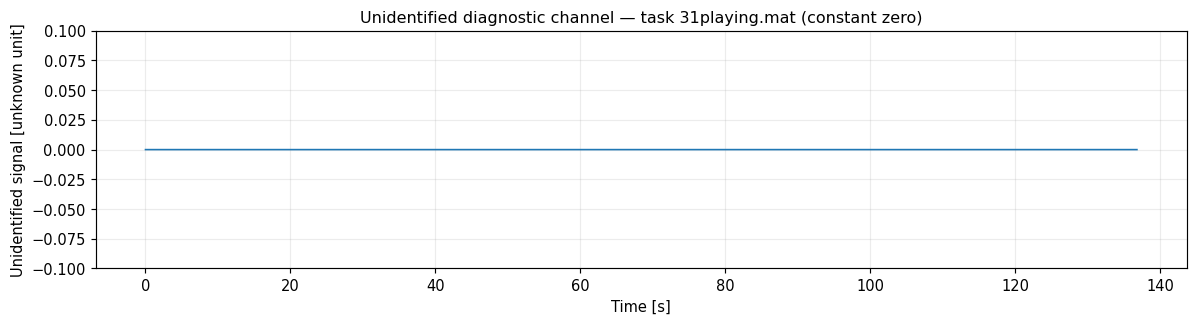

Raw IMU channels cannot be reconstructed from this recording.


In [3]:
fig, ax = plt.subplots(figsize=(11.5, 3.2))
i = indices_for_plot(t1, (None, None))
ax.plot(t1[i], task1_ch[i, 0], linewidth=1.1)
ax.set(xlabel='Time [s]', ylabel='Unidentified signal [unknown unit]',
       title='Unidentified diagnostic channel — task 31playing.mat (constant zero)')
ax.set_ylim(-0.1, 0.1)
export_figure(fig, '01_task1_zero_channel_diagnostic')
print('Raw IMU channels cannot be reconstructed from this recording.')

## 3. Task 2 — Transformations

The Task 2 file contains **eight channels**. The first two are constant zero and have unknown physical interpretation; for clarity they are tabulated but not plotted. Channels **3–8** correspond, in order, to `travel, travel rate, pitch, pitch rate, elevation, elevation rate`. This mapping is supported by the Simulink encoder output order and by numerical differentiation of the recorded angles.

**Important:** These plots show the *available encoder signals*. A synchronous raw-IMU-versus-encoder comparison is not possible from this file alone.
The order of the six nonzero channels is **consistent with**, but cannot be uniquely proved from, the surviving Simulink model and the recorded angle/rate relationships.


> This recording has no synchronised raw IMU channels. Consequently, the angle/rate consistency check below is **encoder-only**; it does not validate the accelerometer or gyro transformation against encoders.

Task 2 auxiliary channels (channels 1–2):
 Channel  Minimum  Maximum  Std
       1      0.0      0.0  0.0
       2     -0.0     -0.0  0.0


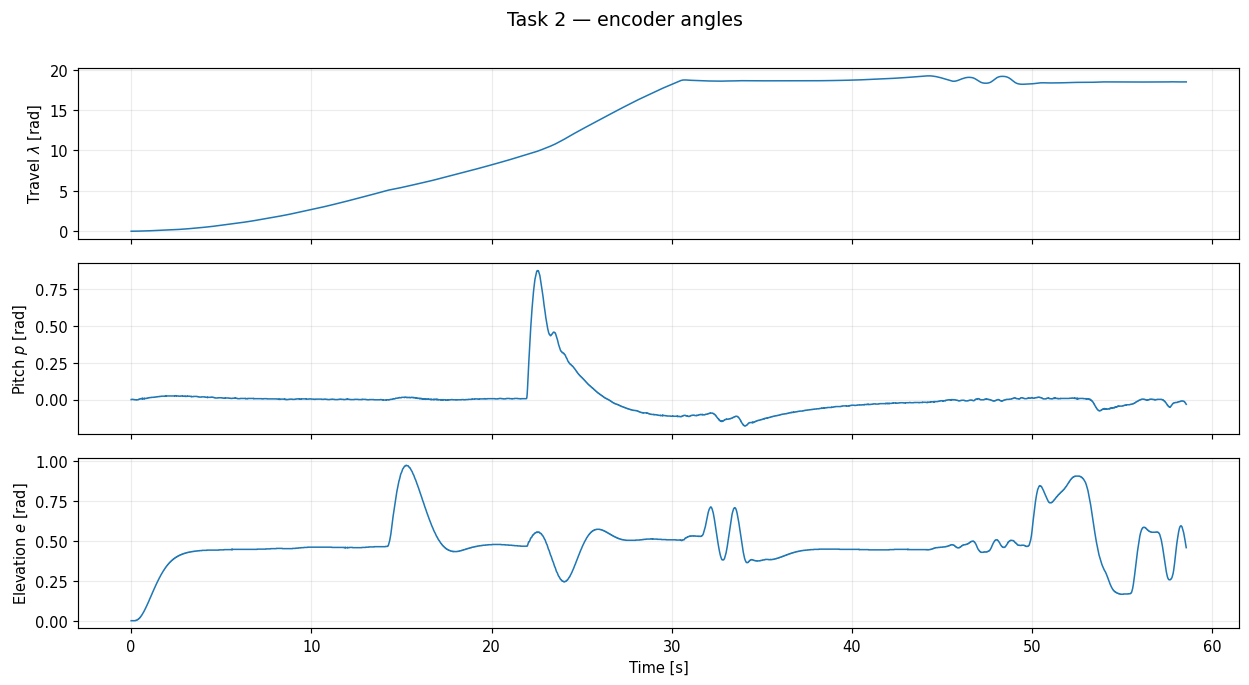

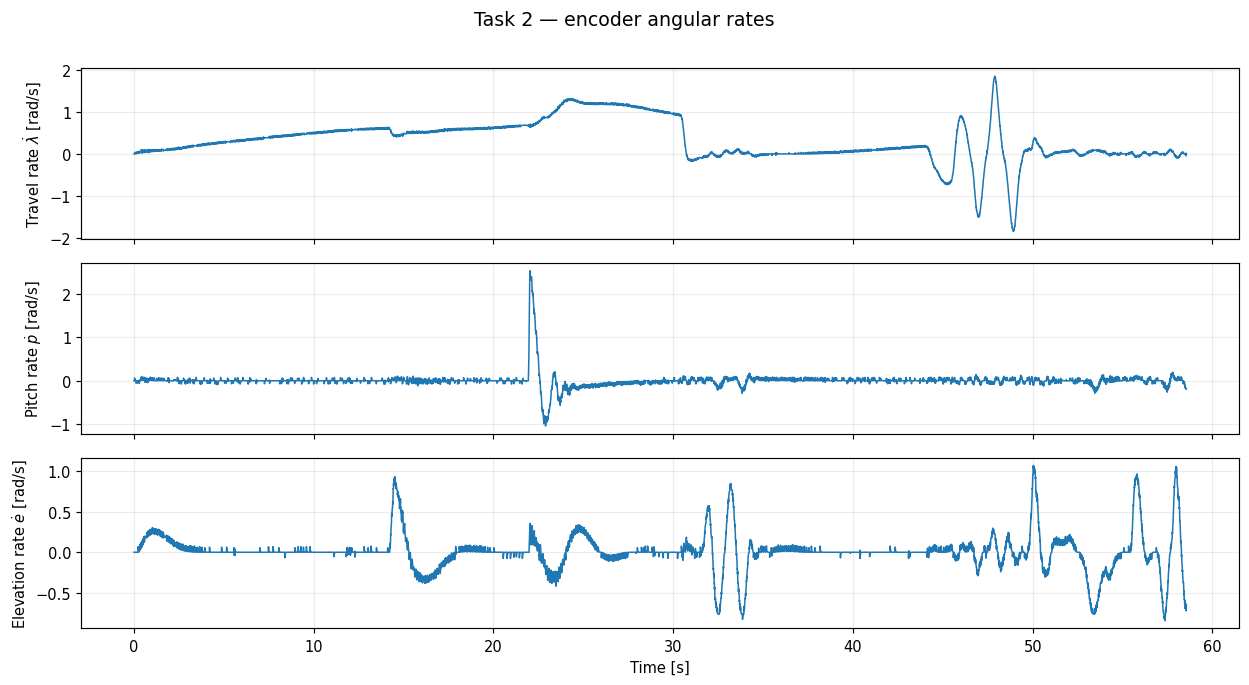

In [4]:
print('Task 2 auxiliary channels (channels 1–2):')
print(pd.DataFrame({
    'Channel': [1, 2],
    'Minimum': np.min(enc_all[:, :2], axis=0),
    'Maximum': np.max(enc_all[:, :2], axis=0),
    'Std': np.std(enc_all[:, :2], axis=0),
}).to_string(index=False))

# The indexed encoder channels (columns 2..7) are grouped as follows:
enc = enc_all[:, 2:]
ANGLE_LABELS = [r'Travel $\lambda$', r'Pitch $p$', r'Elevation $e$']
RATE_LABELS = [r'Travel rate $\dot\lambda$', r'Pitch rate $\dot p$',
               r'Elevation rate $\dot e$']

stacked_plot(t2, enc[:, [0,2,4]], ANGLE_LABELS, ['rad']*3,
             'Task 2 — encoder angles', '02_task2_encoder_angles', TIME_WINDOW_TASK2,
             data_label='Encoder')
stacked_plot(t2, enc[:, [1,3,5]], RATE_LABELS, ['rad/s']*3,
             'Task 2 — encoder angular rates', '03_task2_encoder_rates', TIME_WINDOW_TASK2,
             data_label='Encoder')

### 3.1 Angle–rate consistency check

The recorded encoder rates are compared with the numerical derivatives of the corresponding angles. Differentiation is applied to the full-resolution signals, while figure display may be decimated for legibility.

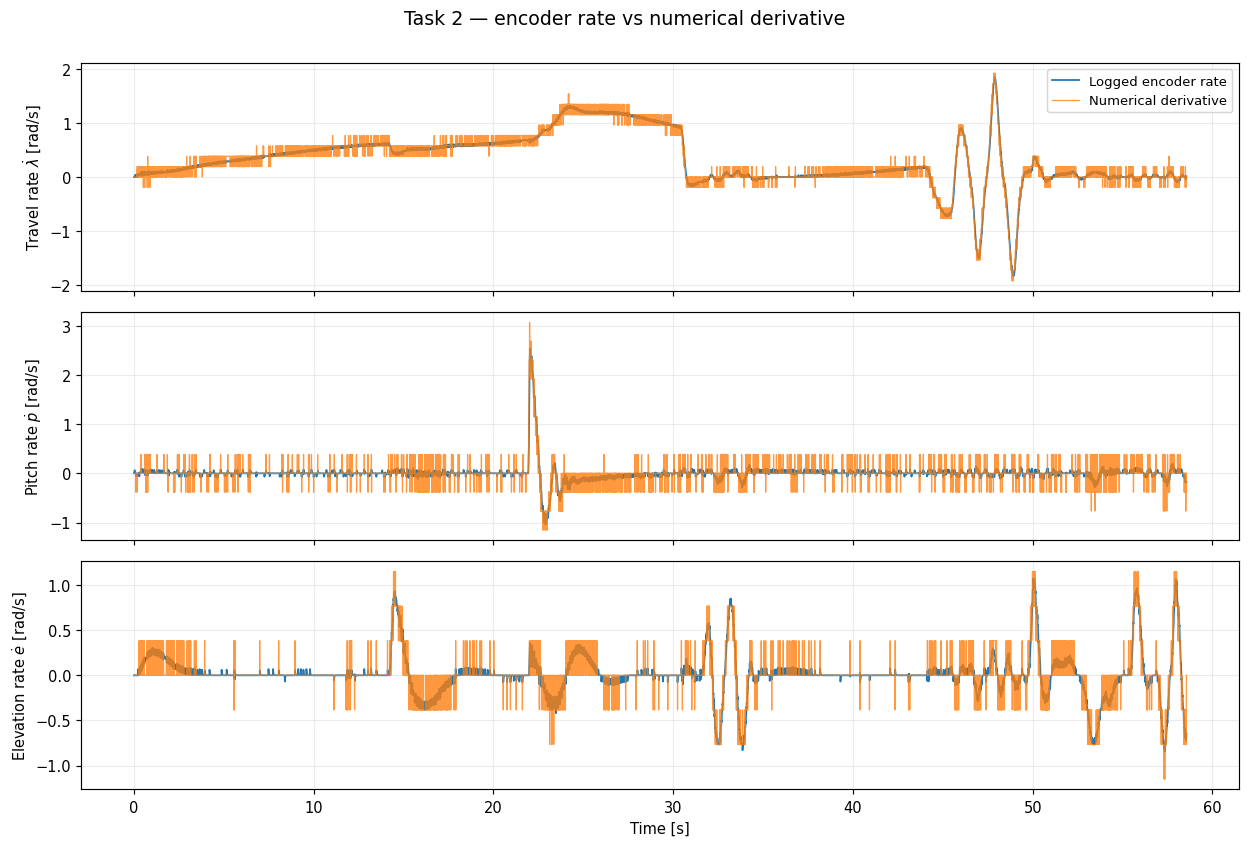

,State,Correlation,MAE [rad/s]
0,Travel,0.9843,0.0659
1,Pitch,0.8008,0.0732
2,Elevation,0.8879,0.0687


In [5]:
idx = indices_for_plot(t2, TIME_WINDOW_TASK2)
fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
consistency = []
for k, ax in enumerate(axs):
    a, r = enc[:, 2*k], enc[:, 2*k+1]
    approximate_rate = np.gradient(a, t2)
    ax.plot(t2[idx], r[idx], label='Logged encoder rate', linewidth=1.2)
    ax.plot(t2[idx], approximate_rate[idx], label='Numerical derivative', linewidth=.85, alpha=.8)
    ax.set_ylabel(f'{RATE_LABELS[k]} [rad/s]')
    if k == 0:
        ax.legend()
    consistency.append({'State': ['Travel','Pitch','Elevation'][k],
                        'Correlation': np.corrcoef(approximate_rate, r)[0,1],
                        'MAE [rad/s]': np.mean(np.abs(approximate_rate - r))})
axs[-1].set_xlabel('Time [s]')
fig.suptitle('Task 2 — encoder rate vs numerical derivative', y=1.002, fontsize=13)
export_figure(fig, '04_task2_angle_rate_consistency')
display(pd.DataFrame(consistency).round(4))

### 3.2 Task 2 — detail around a pitch transient

The six-second detail window uses **all recorded points**. It makes the transient,
quantization effects, and encoder-rate response easier to inspect than in the full-run figure.
Change `ZOOM_WINDOW_TASK2` above to inspect another part of the test.

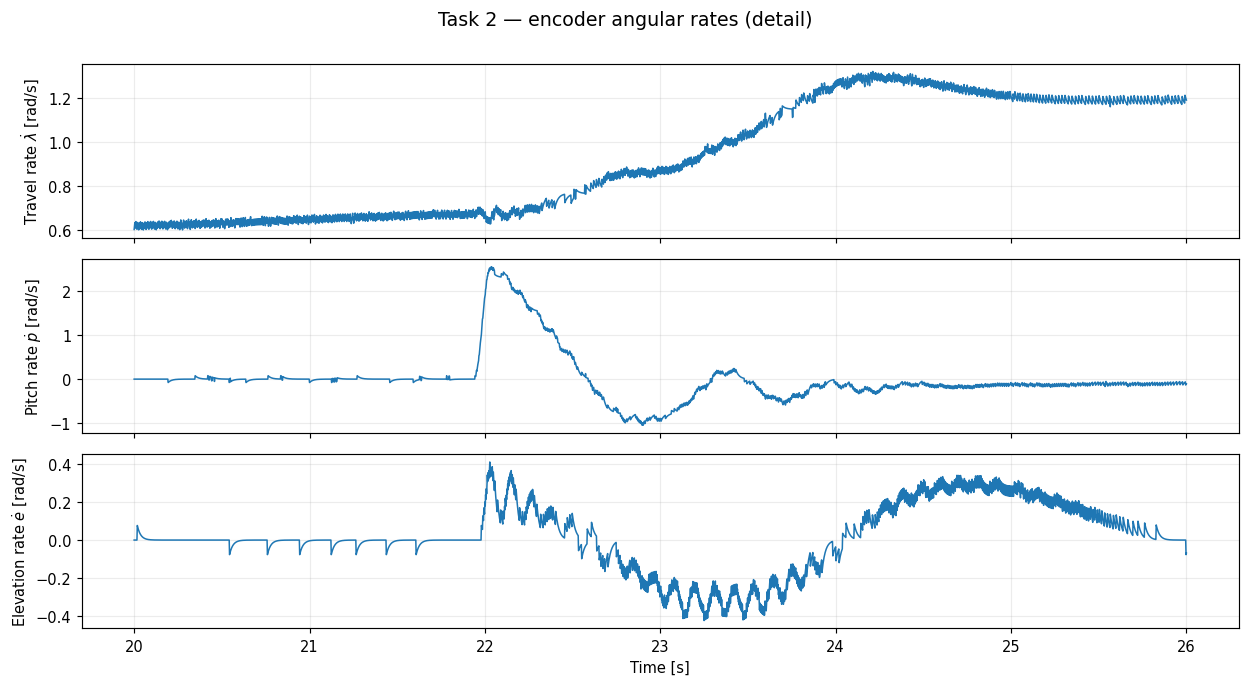

In [6]:
stacked_plot(t2, enc[:, [1,3,5]], RATE_LABELS, ['rad/s']*3,
             'Task 2 — encoder angular rates (detail)',
             '14_task2_encoder_rates_detail', ZOOM_WINDOW_TASK2,
             data_label='Encoder', full_resolution=True)

## 4. Task 3 — Luenberger observer

The exported Simulink model confirms the state order

\[
[y_1,y_2,y_3,y_4,y_5]^T = [p,\dot p,e,\dot e,\dot\lambda]^T.
\]

`task34_y.mat` = IMU-derived measurement vector `y`; `task34_xhat.mat` = observer estimate `xhat`; `task34_u.mat` = control inputs `[V_s, V_d]`. All three have matching timestamps.

The **measurement–estimate residual** is defined by \(r(t) = y(t)-\hat{x}(t)\). It is useful for visual inspection, but cannot be used as an independent estimation error when the observer uses `y` as an input.

This vector was recorded in the Del 3 archive. The `task34_*` files in Del 4 are **not** the same recording and have different durations; they are handled separately in Section 7. The main Simulink file routes the saved measurement vector and observer output to the `To File` blocks. The state ordering follows the observer model, but the exact live parameter file cannot be proved from the recording.

**Model caveat:** The saved observer block uses the workspace variable `B` for the model input. The MATLAB scripts define this variable for an augmented LQR state order rather than for the five-state observer. Additionally, the saved `K2` and `K3` formulas differ from the linearized dynamics. These issues are audited in the accompanying PDF; they are not corrected or compensated for in the recorded measurements.

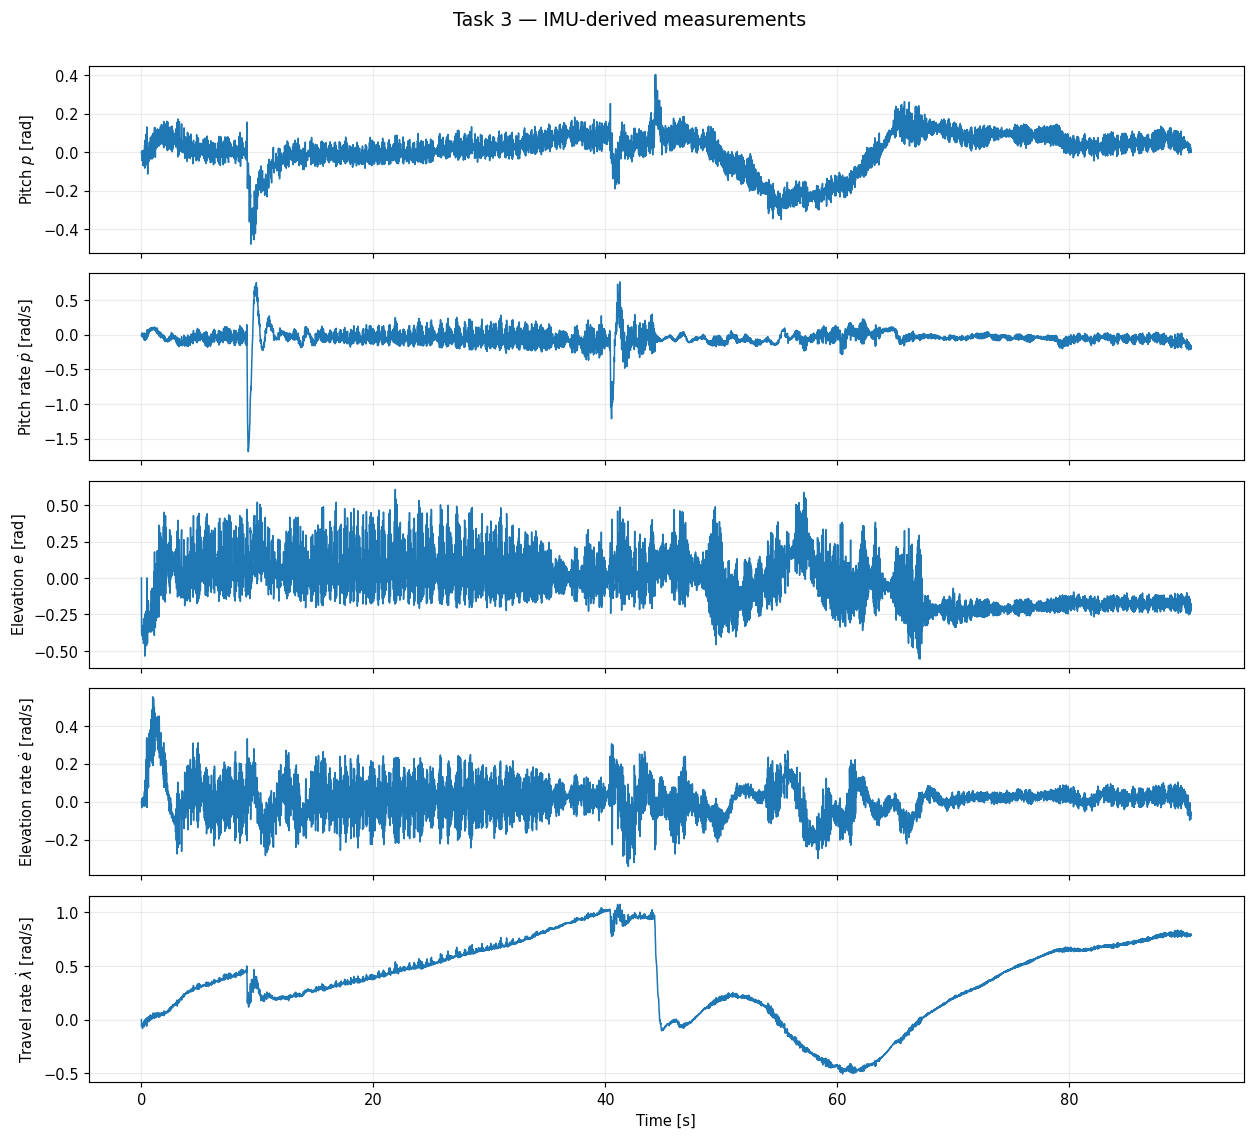

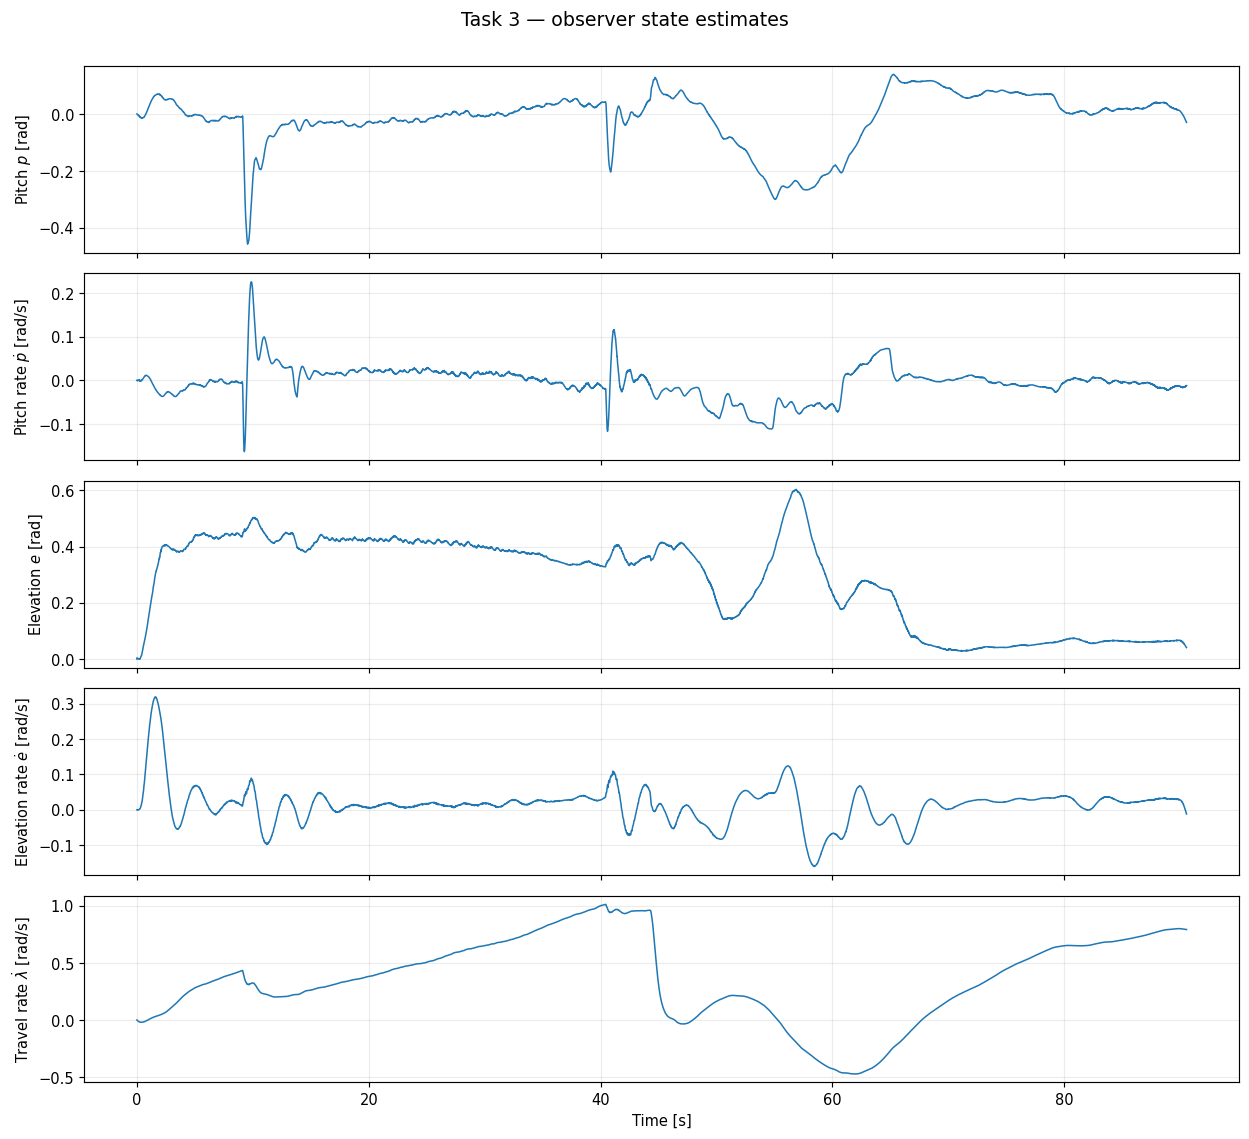

In [7]:
STATE_LABELS = [r'Pitch $p$', r'Pitch rate $\dot p$', r'Elevation $e$',
                r'Elevation rate $\dot e$', r'Travel rate $\dot\lambda$']
STATE_UNITS = ['rad', 'rad/s', 'rad', 'rad/s', 'rad/s']

stacked_plot(t3, y3, STATE_LABELS, STATE_UNITS,
             'Task 3 — IMU-derived measurements',
             '05_task3_measurements', TIME_WINDOW_TASK3,
             data_label='IMU-derived y')
stacked_plot(t3, xhat3, STATE_LABELS, STATE_UNITS,
             'Task 3 — observer state estimates',
             '06_task3_estimates', TIME_WINDOW_TASK3,
             data_label=r'Observer $\hat{x}$')

### 4.1 State-by-state comparison

Plot measured and estimated states directly on top of one another, using the same axes. Individual angle and rate figures provide a less crowded alternative to the complete five-state plot.

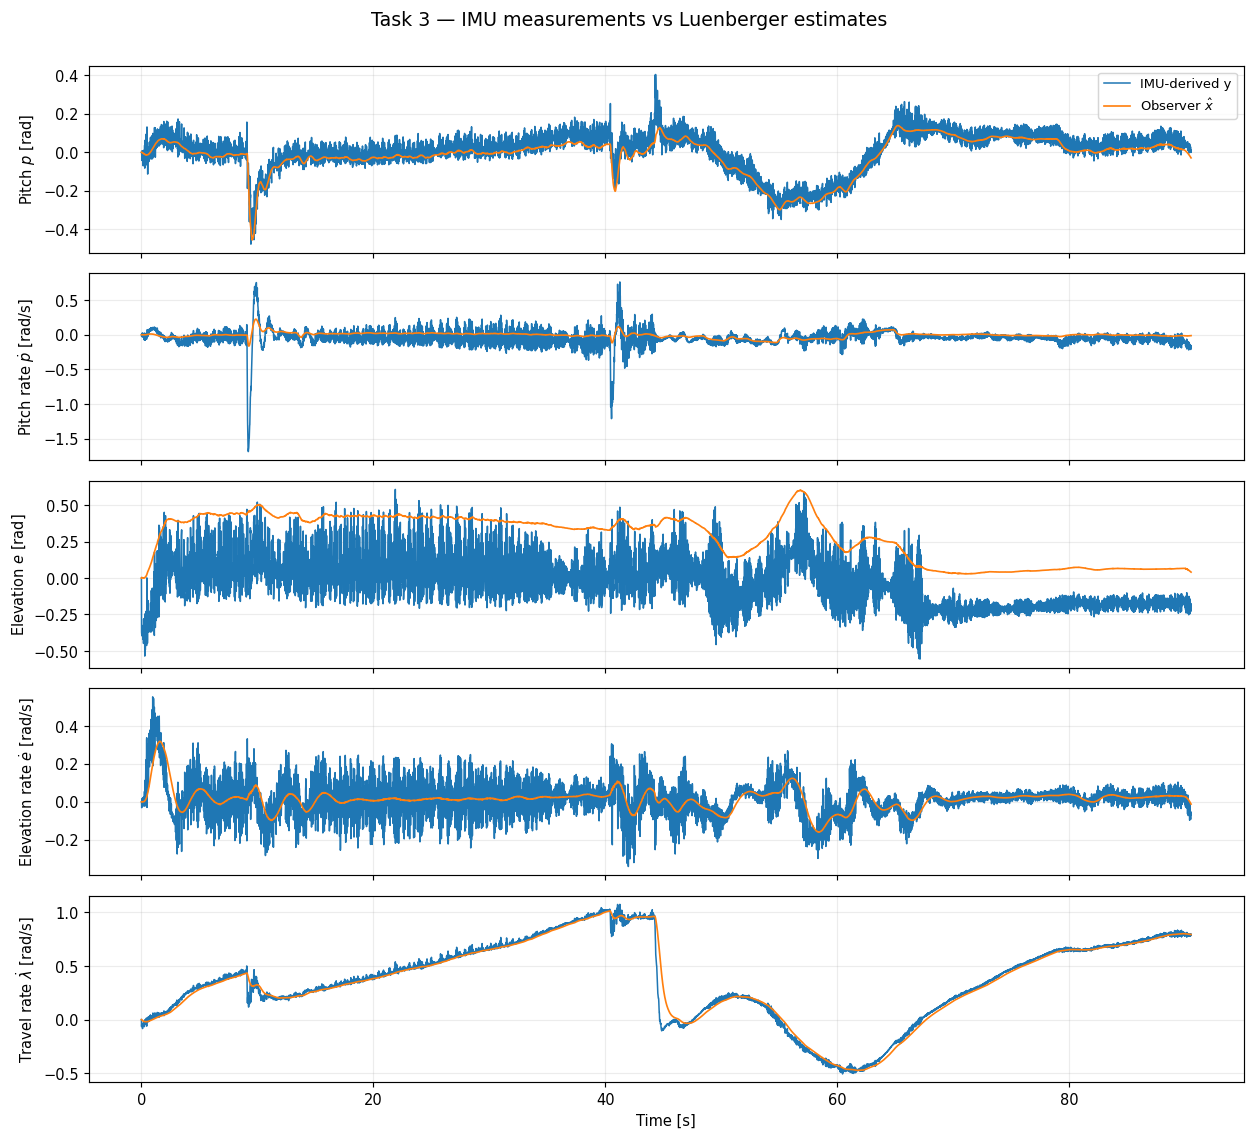

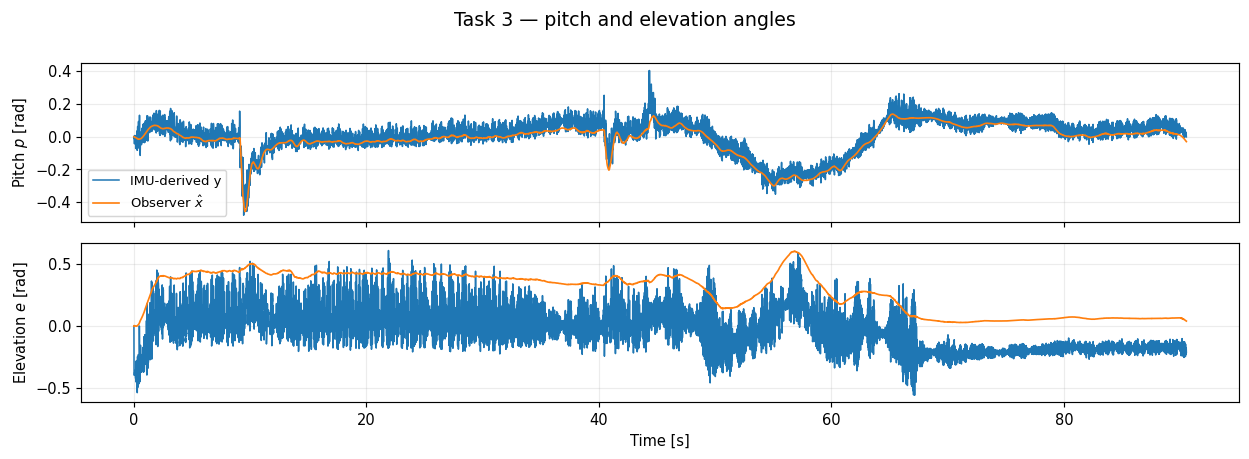

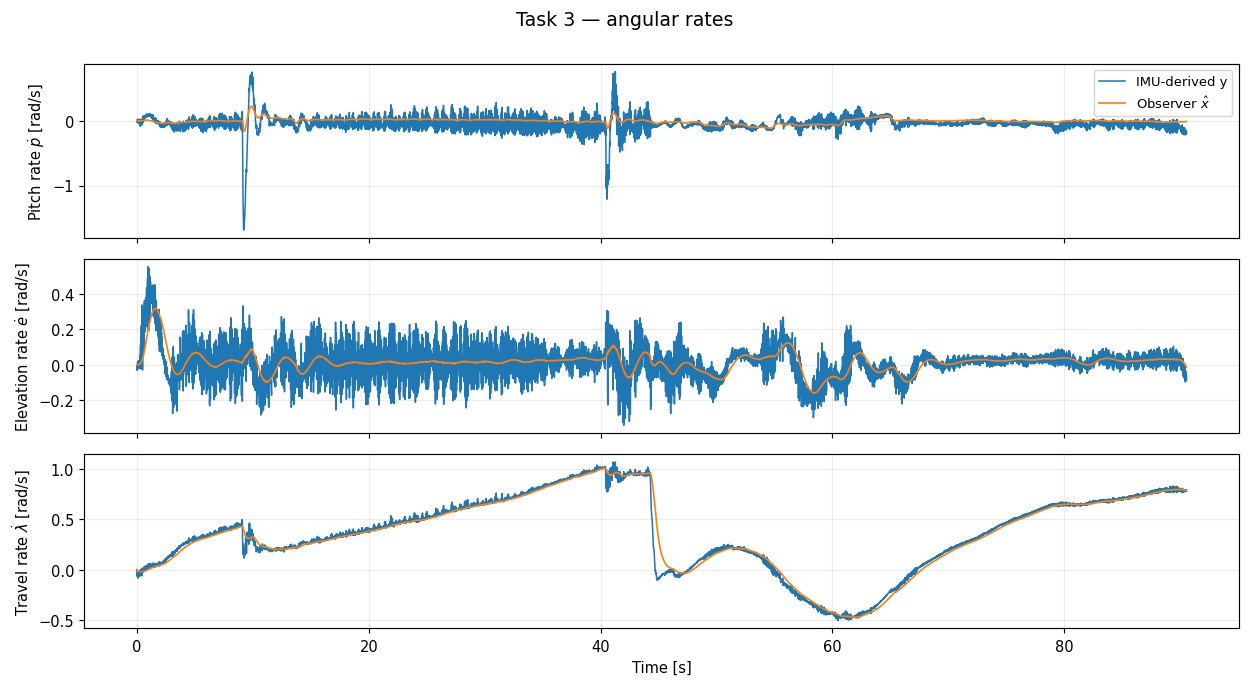

In [8]:
stacked_plot(t3, y3, STATE_LABELS, STATE_UNITS,
             'Task 3 — IMU measurements vs Luenberger estimates',
             '07_task3_measurement_vs_estimate_all', TIME_WINDOW_TASK3,
             comparison=xhat3, comparison_label=r'Observer $\hat{x}$',
             data_label='IMU-derived y')

stacked_plot(t3, y3[:, [0,2]], [STATE_LABELS[k] for k in [0,2]],
             [STATE_UNITS[k] for k in [0,2]],
             'Task 3 — pitch and elevation angles',
             '08_task3_angles_comparison', TIME_WINDOW_TASK3,
             comparison=xhat3[:, [0,2]], comparison_label=r'Observer $\hat{x}$',
             data_label='IMU-derived y')
stacked_plot(t3, y3[:, [1,3,4]], [STATE_LABELS[k] for k in [1,3,4]],
             [STATE_UNITS[k] for k in [1,3,4]],
             'Task 3 — angular rates',
             '09_task3_rates_comparison', TIME_WINDOW_TASK3,
             comparison=xhat3[:, [1,3,4]], comparison_label=r'Observer $\hat{x}$',
             data_label='IMU-derived y')

### 4.1a Task 3 — transient detail

The following overlay uses **full sampled resolution**, unlike the optional decimation
in the full-run plots. It is suited for examining short disturbances, measurement noise,
and differences in response speed. Note that the observer-estimate curve is not an independent
reference measurement: it is the observer estimate driven by the measured signal.

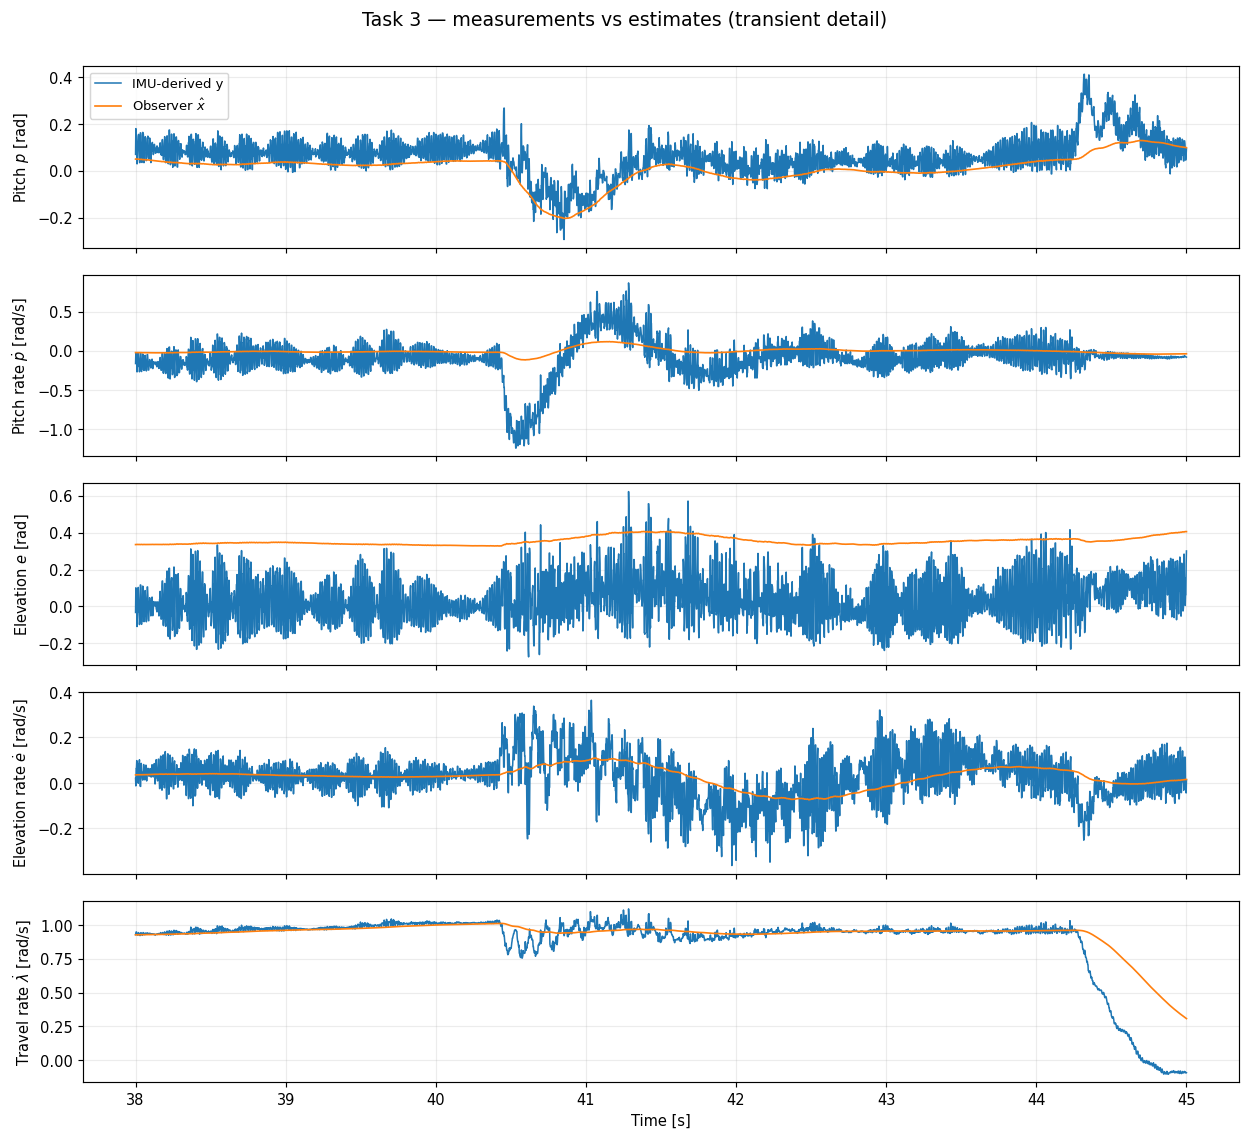

In [9]:
stacked_plot(t3, y3, STATE_LABELS, STATE_UNITS,
             'Task 3 — measurements vs estimates (transient detail)',
             '15_task3_measurement_vs_estimate_detail', ZOOM_WINDOW_TASK3,
             comparison=xhat3, comparison_label=r'Observer $\hat{x}$',
             data_label='IMU-derived y', full_resolution=True)

### 4.2 Residual time series and descriptive statistics

Use `METRICS_WINDOW_TASK3 = (start, end)` in the settings to calculate statistics for a specific interval. **Residual statistics measure agreement with the IMU-derived signal, not accuracy against encoder ground truth.**

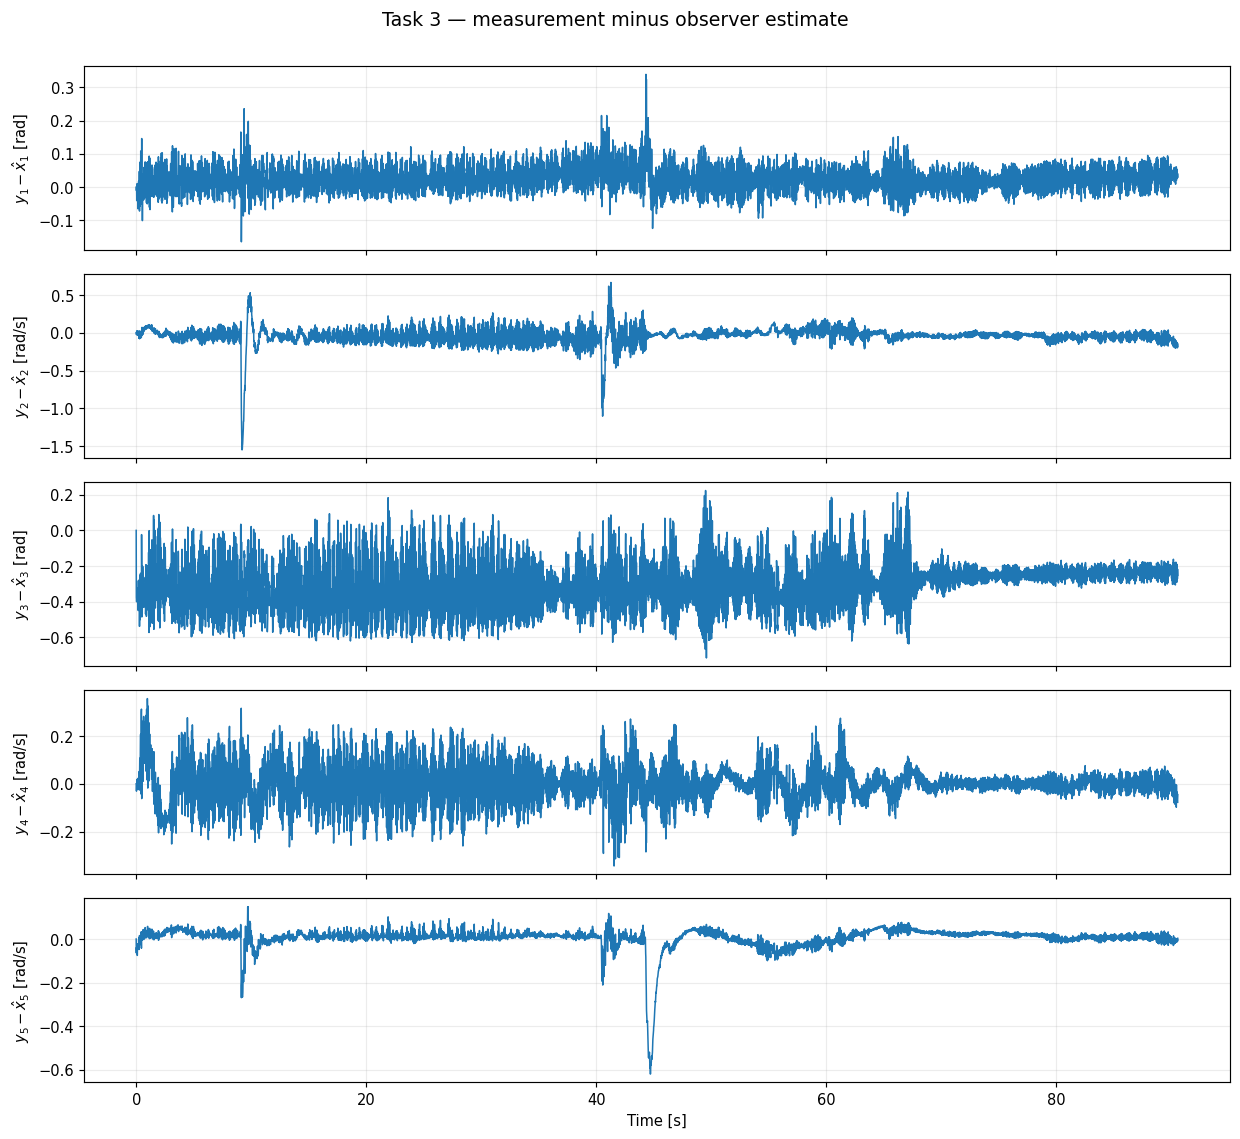

,Window start [s],Window end [s],Sample count,State,Unit,Mean residual,Std residual,MAE,RMSE,Max |residual|
0,0.0,90.54,45271,pitch,rad,0.02384,0.03913,0.03570,0.04582,0.34755
1,0.0,90.54,45271,pitch rate,rad/s,-0.04353,0.11994,0.07562,0.12759,1.62698
2,0.0,90.54,45271,elevation,rad,-0.30536,0.13513,0.30734,0.33392,0.74090
3,0.0,90.54,45271,elevation rate,rad/s,-0.00007,0.08066,0.05833,0.08066,0.36418
4,0.0,90.54,45271,travel rate,rad/s,0.00403,0.05526,0.02693,0.05541,0.62103


In [10]:
residual3 = y3 - xhat3
stacked_plot(t3, residual3, [r'$y_1-\hat{x}_1$', r'$y_2-\hat{x}_2$',
                             r'$y_3-\hat{x}_3$', r'$y_4-\hat{x}_4$',
                             r'$y_5-\hat{x}_5$'], STATE_UNITS,
             'Task 3 — measurement minus observer estimate',
             '10_task3_residuals', TIME_WINDOW_TASK3,
             data_label='y − xhat')

rmask = mask_time(t3, METRICS_WINDOW_TASK3)
resid = residual3[rmask]
metrics = pd.DataFrame({
    'State': ['pitch', 'pitch rate', 'elevation', 'elevation rate', 'travel rate'],
    'Unit': STATE_UNITS,
    'Mean residual': np.mean(resid, axis=0),
    'Std residual': np.std(resid, axis=0, ddof=1),
    'MAE': np.mean(np.abs(resid), axis=0),
    'RMSE': np.sqrt(np.mean(resid**2, axis=0)),
    'Max |residual|': np.max(np.abs(resid), axis=0),
})
metrics.insert(0, 'Window start [s]', float(t3[rmask][0]))
metrics.insert(1, 'Window end [s]', float(t3[rmask][-1]))
metrics.insert(2, 'Sample count', int(rmask.sum()))
display(metrics.round(5))
if SAVE_FIGURES:
    metrics.to_csv(FIGURE_DIR/'task3_residual_statistics.csv', index=False)

### 4.2a Task 3 — residual detail

Plot `y − xhat` around the same transient without display decimation. Residuals are
useful for analyzing agreement between two **non-independent** signals; they are
not the estimation error against a separately measured state.

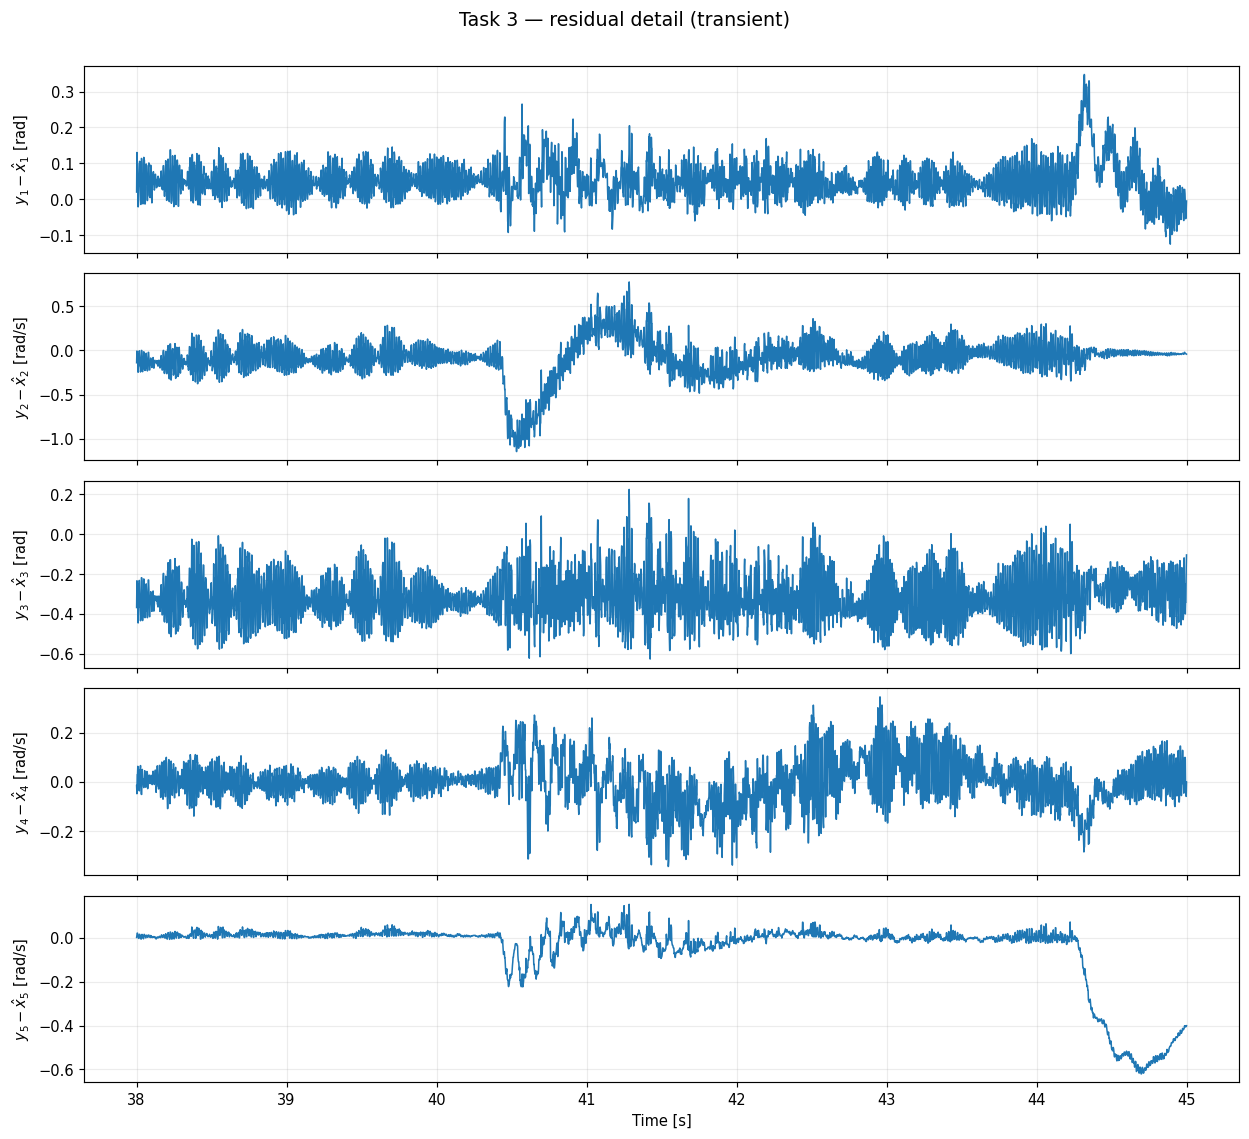

In [11]:
stacked_plot(t3, residual3,
             [r'$y_1-\hat{x}_1$', r'$y_2-\hat{x}_2$', r'$y_3-\hat{x}_3$',
              r'$y_4-\hat{x}_4$', r'$y_5-\hat{x}_5$'],
             STATE_UNITS, 'Task 3 — residual detail (transient)',
             '16_task3_residuals_detail', ZOOM_WINDOW_TASK3,
             data_label=r'$y-\hat{x}$', full_resolution=True)

### 4.3 Residual distributions

The histograms show the distribution of `y − xhat` rather than an independent state-estimation error. Because `density=True` normalizes the integral to 1, the vertical axis has units inverse to those of the residual: `rad⁻¹` for angle residuals and `s/rad` for angular-rate residuals.

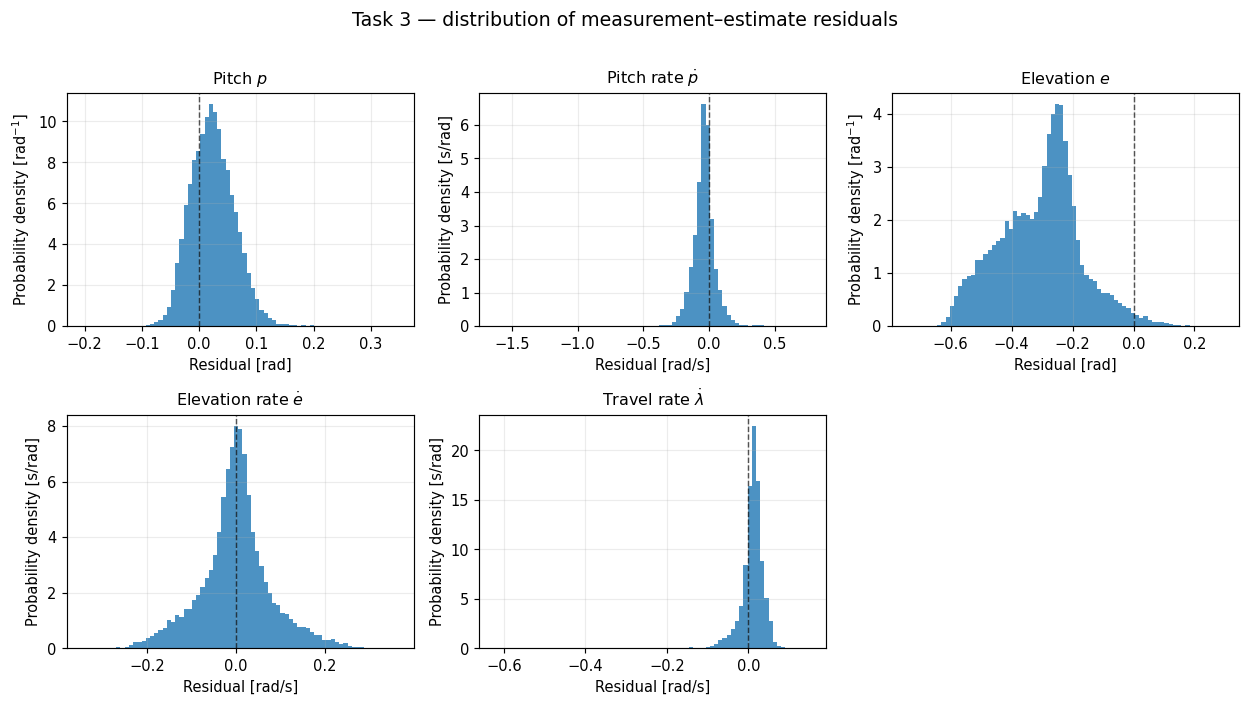

In [12]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6.6))
for k, ax in enumerate(axs.flat):
    if k >= 5:
        ax.axis('off'); continue
    ax.hist(resid[:, k], bins=75, density=True, alpha=.8)
    ax.axvline(0, linewidth=1, linestyle='--', color='black', alpha=.65)
    density_unit = r'rad$^{-1}$' if STATE_UNITS[k] == 'rad' else 's/rad'
    ax.set(title=STATE_LABELS[k], xlabel=f'Residual [{STATE_UNITS[k]}]',
           ylabel=f'Probability density [{density_unit}]')
fig.suptitle('Task 3 — distribution of measurement–estimate residuals', y=1.01, fontsize=13)
export_figure(fig, '11_task3_residual_histograms')

### 4.4 Motor voltage signals

The two channels in `task34_u.mat` correspond to the Simulink voltage sum and difference, \(V_s\) and \(V_d\).

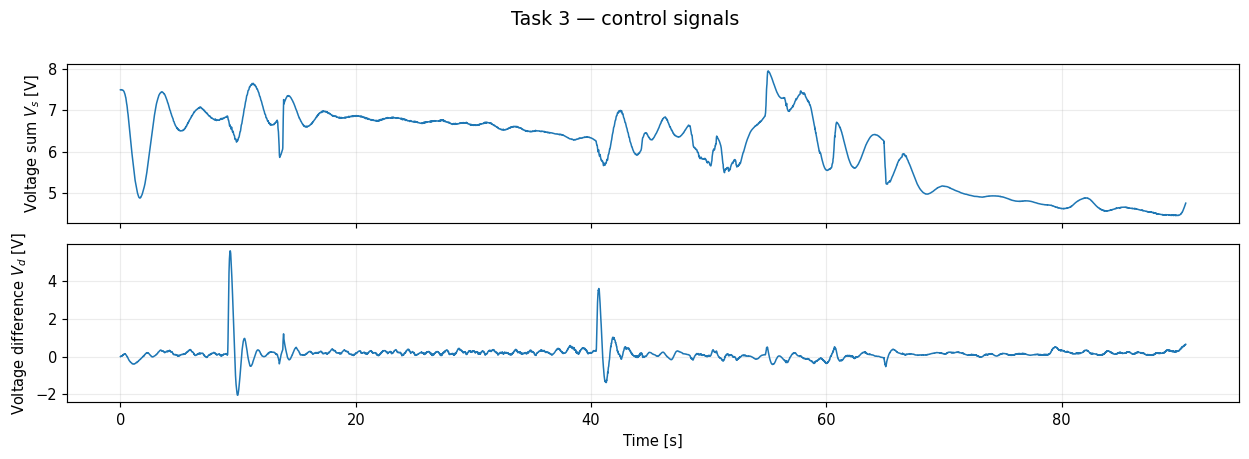

In [13]:
stacked_plot(t3, u3, [r'Voltage sum $V_s$', r'Voltage difference $V_d$'],
             ['V', 'V'], 'Task 3 — control signals', '12_task3_control_voltages',
             TIME_WINDOW_TASK3, data_label='Simulink control output')

### 4.5 Frequency content (optional comparison)

Welch estimates are displayed as **linear power spectral densities on a logarithmic vertical axis**, with physical units consistent with each signal: `rad²/Hz` for angle measurements and `(rad/s)²/Hz` for angular-rate measurements. This avoids the ambiguous `dB/Hz` label (which would require a clearly specified reference quantity). IMU readings may be held constant between sensor updates, so these plots must not be interpreted as independent measurement-noise spectra.

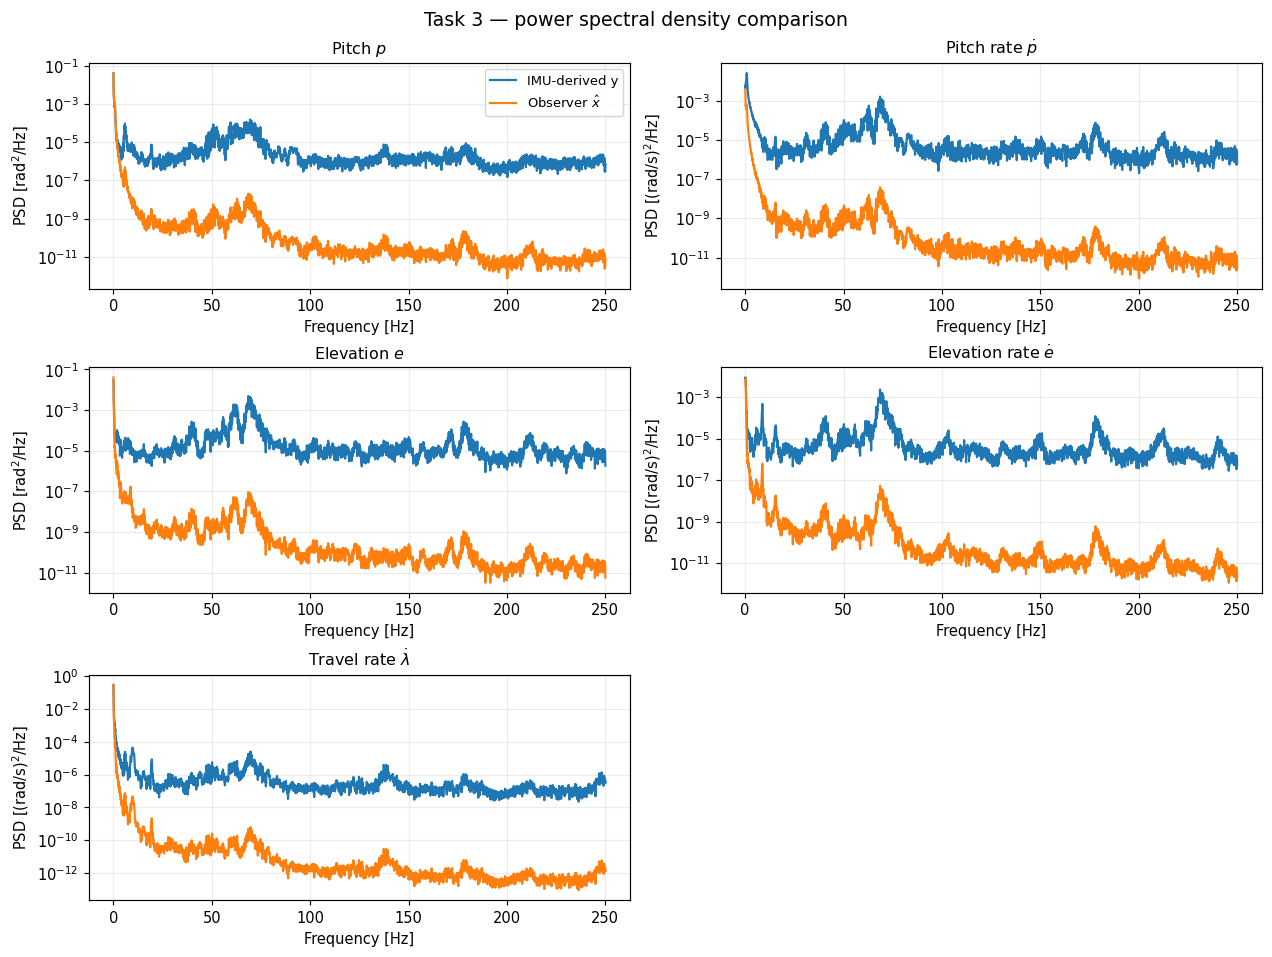

In [14]:
fs = 1 / np.median(np.diff(t3))
fig, axs = plt.subplots(3, 2, figsize=(12, 9), constrained_layout=True)
for k, ax in enumerate(axs.flat):
    if k >= 5:
        ax.axis('off')
        continue
    f, py = welch(y3[:, k], fs=fs, nperseg=min(8192, len(t3)), detrend='constant')
    _, px = welch(xhat3[:, k], fs=fs, nperseg=min(8192, len(t3)), detrend='constant')
    unit_psd = r'rad$^2$/Hz' if STATE_UNITS[k] == 'rad' else r'(rad/s)$^2$/Hz'
    # Logarithmic vertical scale; PSD values retain their physical units.
    ax.semilogy(f[1:], py[1:], label='IMU-derived y')
    ax.semilogy(f[1:], px[1:], label=r'Observer $\hat{x}$')
    ax.set(xlabel='Frequency [Hz]', ylabel=f'PSD [{unit_psd}]', title=STATE_LABELS[k])
    if k == 0:
        ax.legend()
fig.suptitle('Task 3 — power spectral density comparison', fontsize=13)
if SAVE_FIGURES:
    for fmt in FIGURE_FORMATS:
        target = FIGURE_DIR / f'13_task3_psd_comparison.{fmt}'
        fig.savefig(target, dpi=PNG_DPI, bbox_inches='tight')
        exported.append(target)
plt.show()

### 4.6 IMU-derived signal changes / repeated samples

The measurement vector is logged every 2 ms, but the IMU block may hold the most
recent measurements between updates. The recorded `New data` flag is unavailable,
so this section **does not claim to recover the actual IMU update events or its sampling rate**.
It only checks whether the five recorded IMU-derived channels changed between
successive 2-ms samples. Exactly repeated values can occur for other reasons.

A short, full-resolution detail makes this visible without falsely labeling the
value-change indicator as a recorded new-data flag.

The fraction of repeated values is **not** an independently logged new-data flag. It is a heuristic derived from consecutive measurements; identical consecutive readings may also occur without a missed update.

Successive IMU-derived measurement vectors exactly repeated: 21.88%


,Interval between detected changes [ms],Count
0,2.0,25461
1,4.0,9903


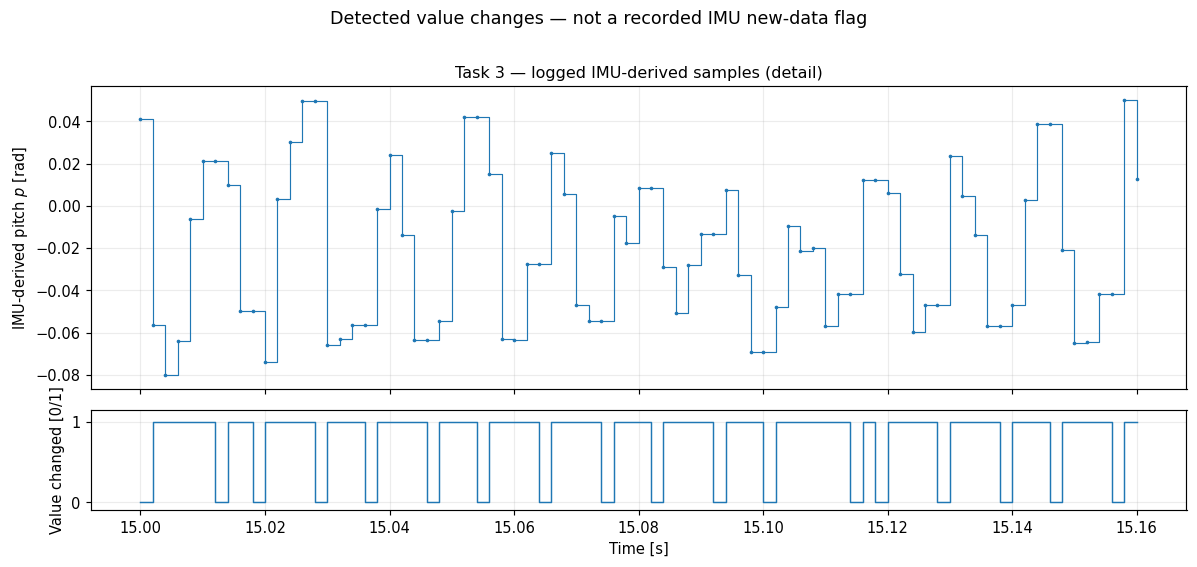

In [15]:
changed = np.r_[False, np.any(np.diff(y3, axis=0) != 0, axis=1)]
repeated_fraction = 1 - np.mean(changed[1:])
change_times = t3[np.flatnonzero(changed)]
change_intervals = np.diff(change_times)
print(f'Successive IMU-derived measurement vectors exactly repeated: {100*repeated_fraction:.2f}%')
if len(change_intervals):
    interval_ms, counts = np.unique(np.round(change_intervals * 1e3, 6), return_counts=True)
    display(pd.DataFrame({'Interval between detected changes [ms]': interval_ms,
                          'Count': counts}))

idx_detail = indices_for_plot(t3, IMU_DETAIL_WINDOW, force_full=True)
fig, axs = plt.subplots(2, 1, figsize=(11.5, 5.3), sharex=True,
                        gridspec_kw={'height_ratios': [3, 1]})
axs[0].step(t3[idx_detail], y3[idx_detail, 0], where='post',
            marker='.', markersize=3, linewidth=.8)
axs[0].set_ylabel(r'IMU-derived pitch $p$ [rad]')
axs[0].set_title('Task 3 — logged IMU-derived samples (detail)')
axs[1].step(t3[idx_detail], changed[idx_detail].astype(int), where='post', linewidth=1.0)
axs[1].set_ylim(-.1, 1.15)
axs[1].set_yticks([0, 1])
axs[1].set_ylabel('Value changed [0/1]')
axs[1].set_xlabel('Time [s]')
fig.suptitle('Detected value changes — not a recorded IMU new-data flag', y=1.01)
export_figure(fig, '17_task3_logged_value_changes_detail')

### 4.7 Early-time measurement–observer comparison

The first eight seconds can reveal initialization offsets or early transients that are hard to see on the full 90.54-second axis. This overlay plots **every recorded sample**, without interpolation, filtering or display decimation. The zoom window is configurable in the settings cell.

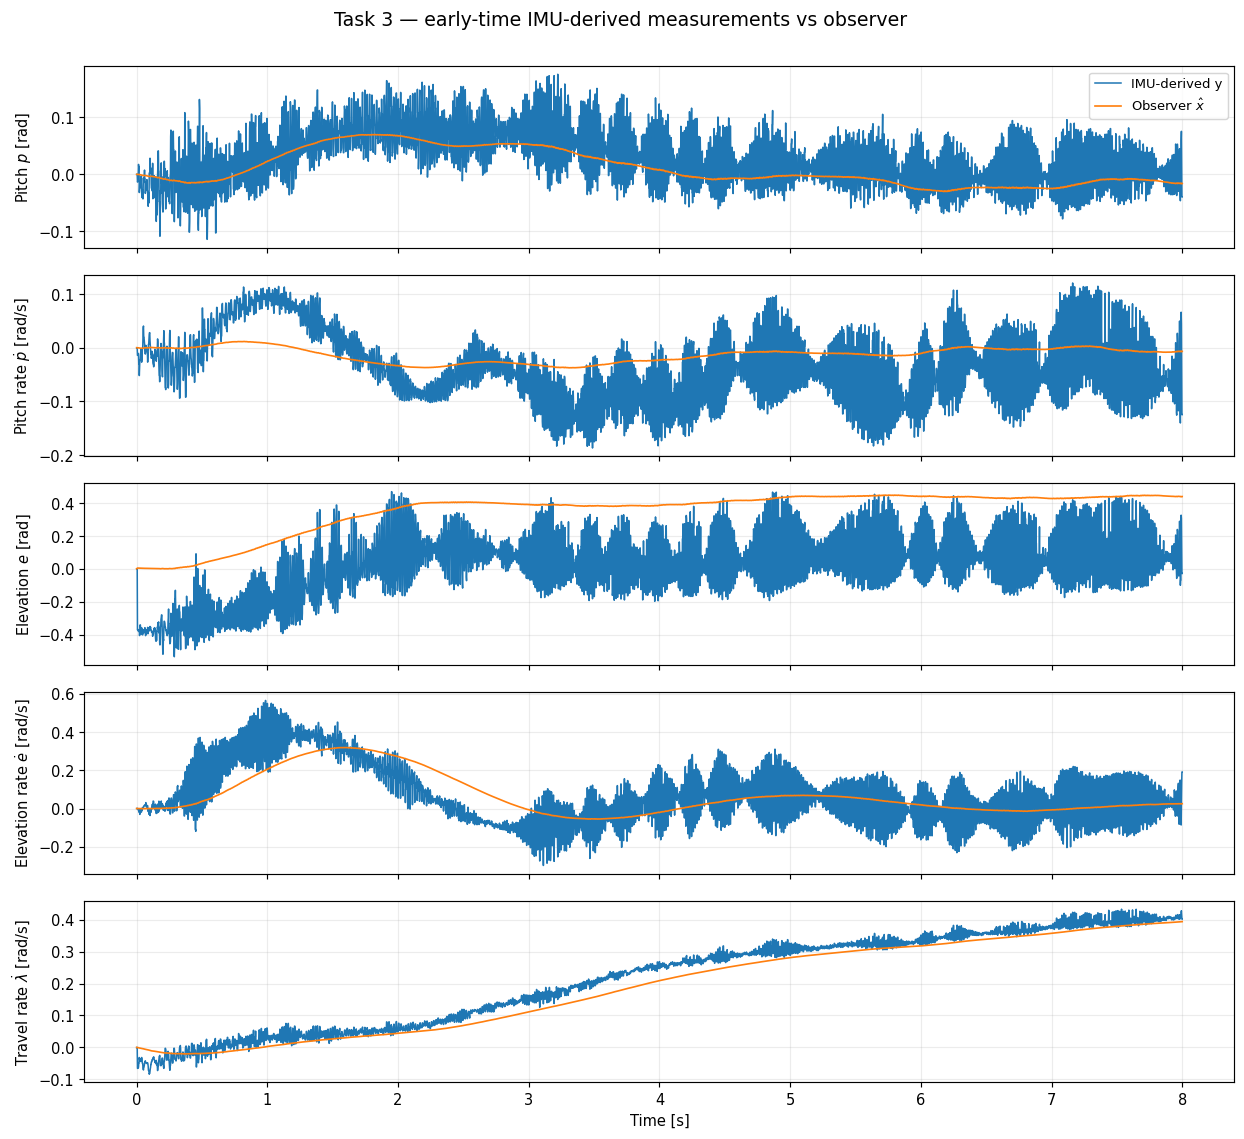

In [16]:
stacked_plot(t3, y3, STATE_LABELS, STATE_UNITS,
             'Task 3 — early-time IMU-derived measurements vs observer',
             '22_task3_early_time_comparison', STARTUP_WINDOW_TASK3,
             comparison=xhat3, comparison_label=r'Observer $\hat{x}$',
             data_label='IMU-derived y', full_resolution=True)

### 4.8 Slow changes in measurement–estimate agreement

A centered rolling mean of each residual is shown as a **descriptive trend**, not an independent estimate of state bias. A one-second window is used by default; points close to the recording boundaries have fewer observations. The original residual remains available in Figures 10 and 16. For clarity, the angles and angular rates retain their own physical units.

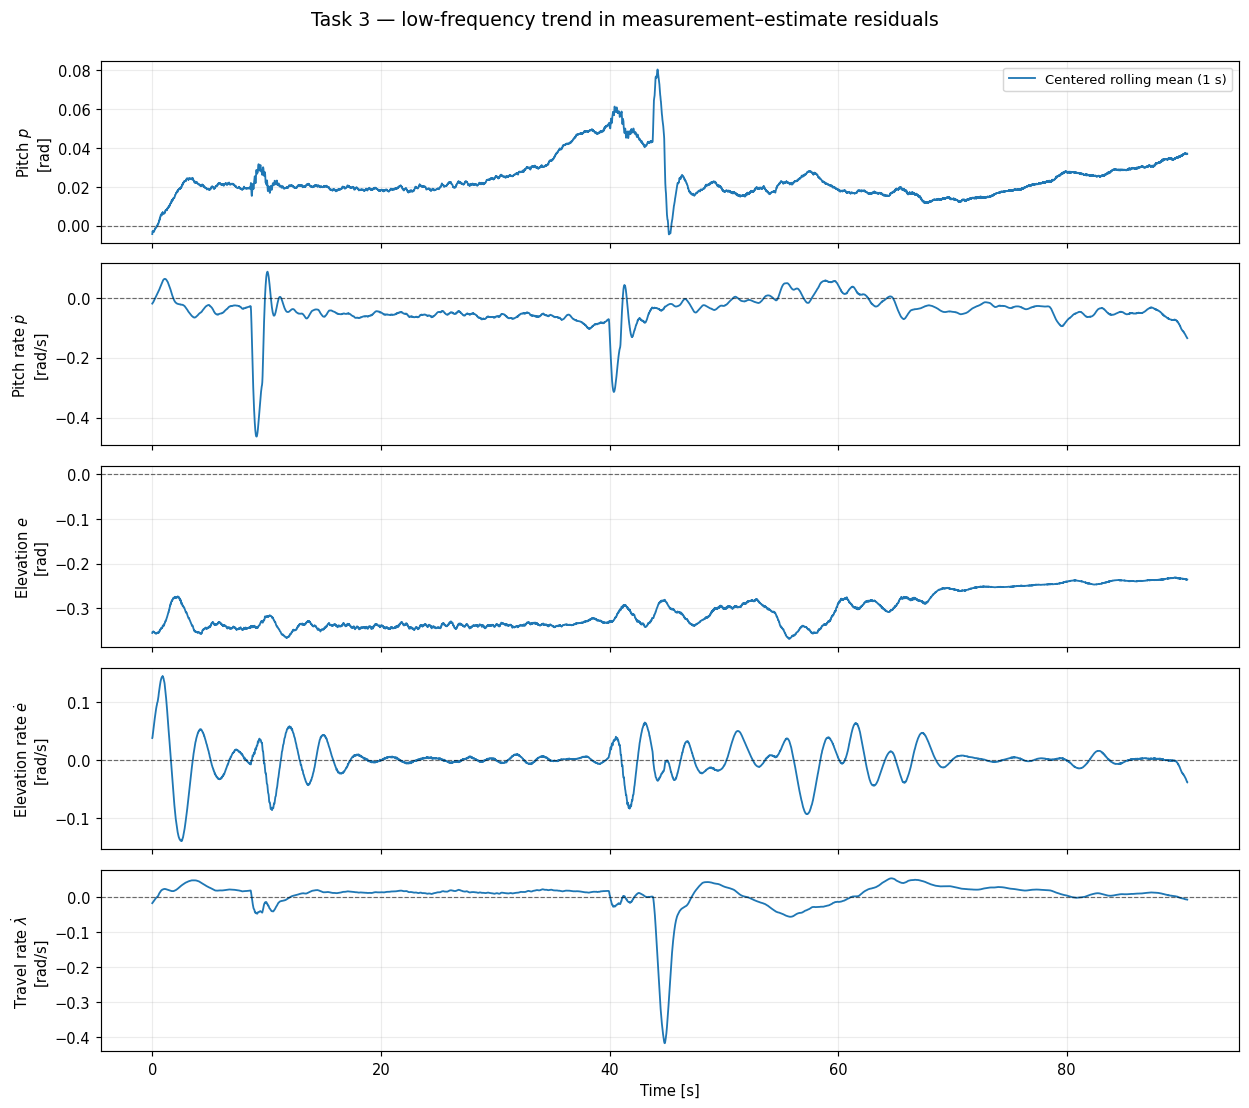

In [17]:
fs_logged = 1 / float(np.median(np.diff(t3)))
trend_samples = max(1, int(round(RESIDUAL_TREND_SECONDS * fs_logged)))
trend = pd.DataFrame(residual3).rolling(window=trend_samples, min_periods=1, center=True).mean().to_numpy()
idx = indices_for_plot(t3, TIME_WINDOW_TASK3)
fig, axes = plt.subplots(5, 1, figsize=(12, 10.5), sharex=True)
for k, ax in enumerate(axes):
    ax.plot(t3[idx], trend[idx, k], lw=1.25, label=f'Centered rolling mean ({RESIDUAL_TREND_SECONDS:g} s)')
    ax.axhline(0, color='black', alpha=.55, lw=.8, ls='--')
    ax.set_ylabel(f'{STATE_LABELS[k]}\n[{STATE_UNITS[k]}]')
axes[0].legend(loc='best')
axes[-1].set_xlabel('Time [s]')
fig.suptitle('Task 3 — low-frequency trend in measurement–estimate residuals', y=1.001, fontsize=13)
export_figure(fig, '23_task3_residual_trend')

## 5. Data that cannot be treated as a time-series

`taskpocomneg1j10.mat` has only one column with seven values. There is no recorded time axis or state metadata, so it is displayed below as a vector rather than mislabelled as a time-series.

In [18]:
snapshot = load_recording('taskpocomneg1j10.mat').ravel()
display(pd.DataFrame({'Vector element (1-based)': np.arange(1, len(snapshot)+1),
                      'Recorded value': snapshot}).round(5))

,Vector element (1-based),Recorded value
0,1,0.00
1,2,0.00
2,3,0.00
3,4,-0.00
4,5,0.00
5,6,-0.53
6,7,0.00


## 6. Coverage of the main Lab 3 files

All six original experimental `.mat` files are loaded. Constant channels are documented rather than assigned guessed physical meanings. The seven-value snapshot has no valid time axis and is shown as a table. Only the additional `task34_*` recordings from the second archive appear below; there are no Lab 4 experiments in this notebook.


## 7. Additional `task34_*` recordings recovered from the second archive

The second ZIP also contains four *different* `task34_*` recordings: `xhat` (2.392 s), `y` (36.038 s; a single zero-valued channel), and **two different** files originally called `task34_u.mat`: 65.400 s (zero input channels) and 131.706 s (varying inputs). The shorter input recording has been given the local filename `task34_u_early.mat` to avoid overwriting the other.

**These are not synchronized with one another or with the main Lab 3 recording.** Their connection to particular observer settings is unverified, and their signal units and identities cannot always be established. The long extra `task34_u` recording contains values around −50 to +59; **without a verified actuator scaling, these must not be reported as actual motor voltages**. They are included only because their filenames are explicitly `task34_*` and they may belong to the late Part III work. Do not compare their samples across files or compute residuals between them.


In [19]:
def load_extra(name):
    path = EXTRA_DIR / name
    if not path.exists():
        raise FileNotFoundError(f'Missing extra recording: {path}')
    arr = np.asarray(loadmat(path)['ans'], dtype=float)
    if arr.ndim != 2 or arr.shape[1] < 3 or not np.isfinite(arr).all():
        raise ValueError(f'Invalid auxiliary series {name}: {arr.shape}')
    t = arr[0]
    if not np.all(np.diff(t) > 0):
        raise ValueError(f'Non-monotonic time for auxiliary {name}')
    return t, arr[1:].T

extra_names = ['task34_xhat.mat', 'task34_y.mat', 'task34_u.mat', 'task34_u_early.mat']
extra = {n:load_extra(n) for n in extra_names}
extra_summary = pd.DataFrame([{
    'Additional Lab 3-named MAT file': n, 'Channels': x.shape[1], 'Samples': len(t),
    'Duration [s]': round(float(t[-1] - t[0]), 3),
    'Nonconstant channels': int(np.count_nonzero(np.ptp(x, axis=0)))
} for n,(t,x) in extra.items()])
display(extra_summary)
assert len({len(t) for t,_ in extra.values()}) == 4, 'Unexpectedly matching sample counts; recheck data origin.'


,Additional Lab 3-named MAT file,Channels,Samples,Duration [s],Nonconstant channels
0,task34_xhat.mat,5,1197,2.392,5
1,task34_y.mat,1,18020,36.038,0
2,task34_u.mat,2,65854,131.706,2
3,task34_u_early.mat,2,32701,65.400,0


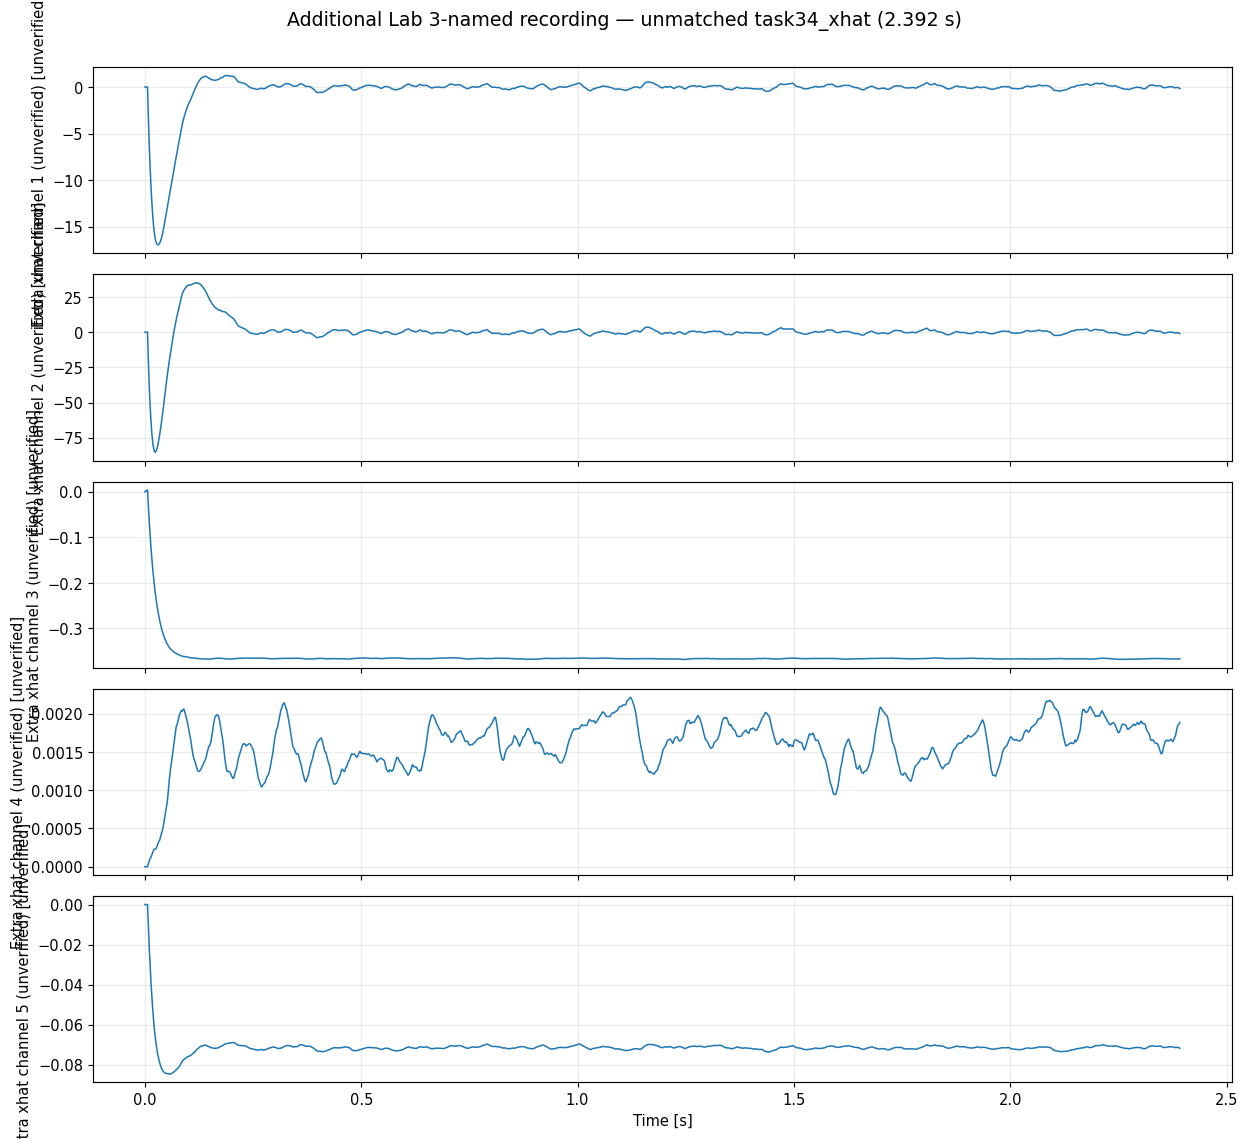

In [20]:
t_extra, x_extra = extra['task34_xhat.mat']
stacked_plot(t_extra, x_extra,
    [f'Extra xhat channel {i+1} (unverified)' for i in range(x_extra.shape[1])],
    ['unverified']*x_extra.shape[1],
    'Additional Lab 3-named recording — unmatched task34_xhat (2.392 s)',
    '18_supplementary_task34_xhat', full_resolution=True,
    data_label='Unmatched extra xhat')


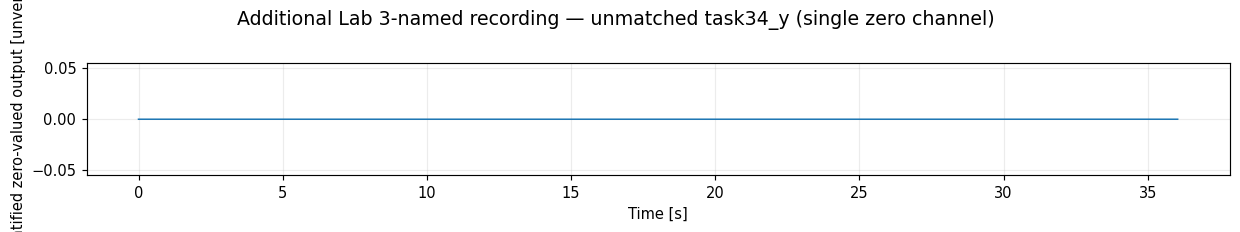

In [21]:
t_extra, x_extra = extra['task34_y.mat']
stacked_plot(t_extra, x_extra, ['Unidentified zero-valued output'], ['unverified'],
    'Additional Lab 3-named recording — unmatched task34_y (single zero channel)',
    '19_supplementary_task34_y', data_label='Unidentified zero signal')


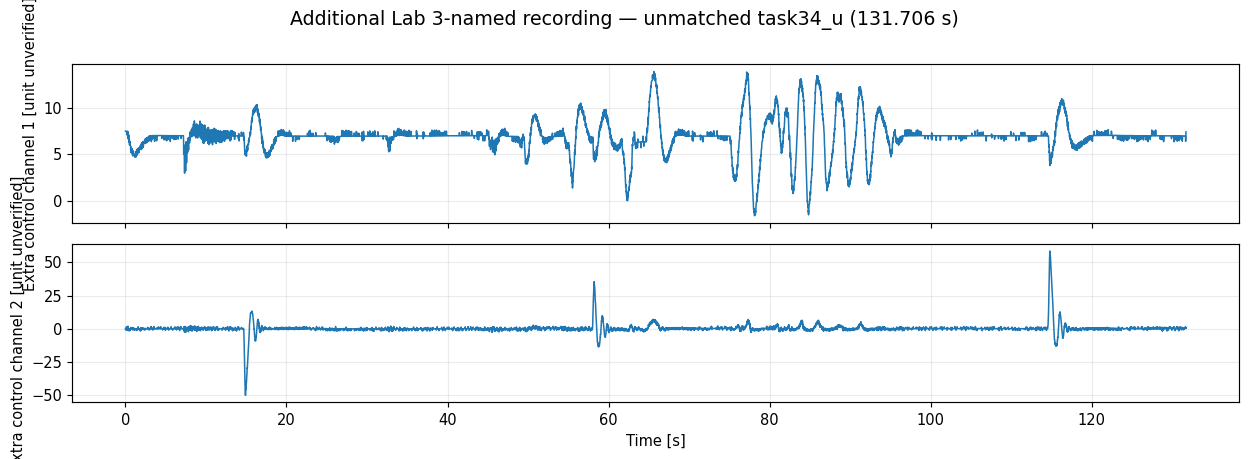

In [22]:
t_extra, x_extra = extra['task34_u.mat']
stacked_plot(t_extra, x_extra,
    [f'Extra control channel {i+1}' for i in range(x_extra.shape[1])],
    ['unit unverified']*x_extra.shape[1],
    'Additional Lab 3-named recording — unmatched task34_u (131.706 s)',
    '20_supplementary_task34_u', data_label='Unmatched extra u')


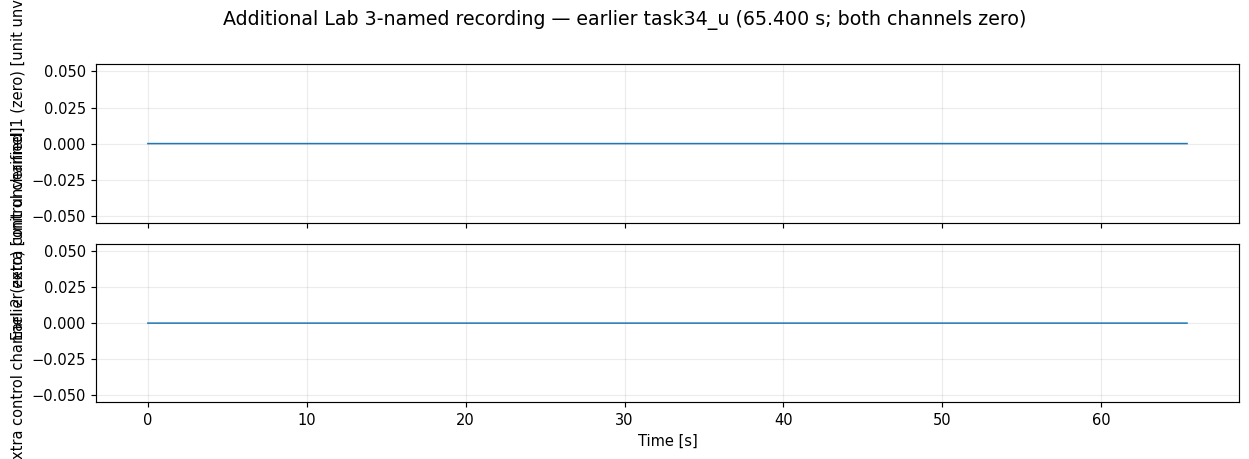

In [23]:
t_extra0, x_extra0 = extra['task34_u_early.mat']
stacked_plot(t_extra0, x_extra0,
    [f'Earlier extra control channel {i+1} (zero)' for i in range(x_extra0.shape[1])],
    ['unit unverified']*x_extra0.shape[1],
    'Additional Lab 3-named recording — earlier task34_u (65.400 s; both channels zero)',
    '21_supplementary_task34_u_early_zero', data_label='Unmatched earlier u')


## 8. Lab 3 file audit and figure list

The `Lab3_filoversikt.csv` manifest includes the six Lab 3 original MAT files and four distinct additional `task34_*` recordings found in the second supplied archive. It records original paths and SHA-256 hashes so that identically named files cannot be confused.

**Remaining gaps (Lab 3 only):** no verified synchronized raw accelerometer/gyro and encoder data for Tasks 1–2; only one usable synchronized five-state measurement/observer/input set for Task 3; no clearly linked repeat runs with alternative observer pole locations or `C` matrices.

`reference/` contains selected MATLAB/Simulink files taken **only from the Del 3 archive**. They are preserved as references; this notebook does not execute them.


In [24]:
# Summary and final figure register — Lab 3 only.
manifest_path = Path('Lab3_filoversikt.csv')
if manifest_path.exists():
    lab3_manifest = pd.read_csv(manifest_path)
    display(lab3_manifest[['Source', 'Package_file', 'Channels', 'Duration_s', 'Synchronization']])
else:
    print('Lab 3 file manifest not found; plotting does not depend on the manifest.')

coverage = pd.DataFrame([
    ('Lab 3 original', 'task 31playing.mat', 1, 'Unidentified all-zero diagnostic'),
    ('Lab 3 original', 'task 2b byson.mat', 8, 'Six encoder channels + two zero-valued channels'),
    ('Lab 3 original', 'task34_y.mat', 5, 'Five synchronized IMU-derived measurements'),
    ('Lab 3 original', 'task34_xhat.mat', 5, 'Five synchronized observer estimates'),
    ('Lab 3 original', 'task34_u.mat', 2, 'Two synchronized voltage/control channels'),
    ('Lab 3 original', 'taskpocomneg1j10.mat', 7, 'Single vector without time axis'),
    ('Second archive / Lab 3-named', 'task34_xhat.mat', 5, 'Separate short estimate-like recording'),
    ('Second archive / Lab 3-named', 'task34_y.mat', 1, 'Separate zero-valued diagnostic recording'),
    ('Second archive / Lab 3-named', 'task34_u.mat', 2, 'Separate varying-input recording'),
    ('Second archive / Lab 3-named', 'task34_u_early.mat', 2, 'Separate zero-input recording; originally called task34_u.mat'),
], columns=['Source', 'File', 'Signals', 'Treatment'])
display(coverage)
coverage.to_csv('data_coverage.csv', index=False)
figure_index = pd.DataFrame([{'Figure filename': p.name, 'Size [KiB]': round(p.stat().st_size/1024, 1)}
                             for p in sorted(set(exported)) if p.suffix.lower() == '.png'])
figure_index.to_csv('figure_index.csv', index=False)
display(figure_index)
print(f'Exported {len(figure_index)} distinct Lab 3 PNG figures (+ SVG).')
if not SAVE_FIGURES:
    print('SAVE_FIGURES=False: only in-memory figures were created; no figures exported.')


,Source,Package_file,Channels,Duration_s,Synchronization
0,Del 3(1).zip,data/Hovedopptak_Del3/task 31playing.mat,1,136.800,Separate Task 1/2 file or single vector
1,Del 3(1).zip,data/Hovedopptak_Del3/task 2b byson.mat,8,58.552,Separate Task 1/2 file or single vector
2,Del 3(1).zip,data/Hovedopptak_Del3/task34_y.mat,5,90.540,Synced with other task34 main files
3,Del 3(1).zip,data/Hovedopptak_Del3/task34_xhat.mat,5,90.540,Synced with other task34 main files
4,Del 3(1).zip,data/Hovedopptak_Del3/task34_u.mat,2,90.540,Synced with other task34 main files
5,Del 3(1).zip,data/Hovedopptak_Del3/taskpocomneg1j10.mat,7,NaN,Separate Task 1/2 file or single vector
6,Del 4(1).zip (Lab 3-named only),data/Tillegg_Lab3_fra_annet_arkiv/task34_y.mat,1,36.038,Not synced / independently logged
7,Del 4(1).zip (Lab 3-named only),data/Tillegg_Lab3_fra_annet_arkiv/task34_xhat.mat,5,2.392,Not synced / independently logged
8,Del 4(1).zip (Lab 3-named only),data/Tillegg_Lab3_fra_annet_arkiv/task34_u.mat,2,131.706,Not synced / independently logged
9,Del 4(1).zip (Lab 3-named only),data/Tillegg_Lab3_fra_annet_arkiv/task34_u_ear...,2,65.400,Not synced / independently logged


,Source,File,Signals,Treatment
0,Lab 3 original,task 31playing.mat,1,Unidentified all-zero diagnostic
1,Lab 3 original,task 2b byson.mat,8,Six encoder channels + two zero-valued channels
2,Lab 3 original,task34_y.mat,5,Five synchronized IMU-derived measurements
3,Lab 3 original,task34_xhat.mat,5,Five synchronized observer estimates
4,Lab 3 original,task34_u.mat,2,Two synchronized voltage/control channels
5,Lab 3 original,taskpocomneg1j10.mat,7,Single vector without time axis
6,Second archive / Lab 3-named,task34_xhat.mat,5,Separate short estimate-like recording
7,Second archive / Lab 3-named,task34_y.mat,1,Separate zero-valued diagnostic recording
8,Second archive / Lab 3-named,task34_u.mat,2,Separate varying-input recording
9,Second archive / Lab 3-named,task34_u_early.mat,2,Separate zero-input recording; originally call...


,Figure filename,Size [KiB]
0,01_task1_zero_channel_diagnostic.png,61.6
1,02_task2_encoder_angles.png,144.0
2,03_task2_encoder_rates.png,200.1
3,04_task2_angle_rate_consistency.png,288.4
4,05_task3_measurements.png,421.1
5,06_task3_estimates.png,317.3
6,07_task3_measurement_vs_estimate_all.png,545.8
7,08_task3_angles_comparison.png,237.7
8,09_task3_rates_comparison.png,292.4
9,10_task3_residuals.png,435.7


Exported 23 distinct Lab 3 PNG figures (+ SVG).
